# A faster conditional displacement (CD): stronger sideband, same 30 ns π pulses

**Yes.** With a 2× stronger sideband (300 ns swap), the same 30 ns π pulses, and each pulse's qubit phase and each cell's sideband phase chosen by an optimiser, the CD gets **faster at a chosen fidelity, with a tradeoff that depends on the pulse count**. Ideal coherent model, every input up to Fock 10:

| | today: 600 ns swap, X X X̄ X̄, 20 ns gaps | 300 ns swap, optimised phases |
|---|---|---|
| CD β = 1 | 0.81 µs, 99.803 % | **0.49 µs, 99.66 %**, or 0.73 µs, 99.93 % |
| CD β = 2 | 1.61 µs, 99.219 % | **0.97 µs, 99.33 %**, or 1.45 µs, 99.93 % |

Simply doubling the sideband with today's pattern makes the CD faster with substantially larger error (Section 2). The historical free-phase candidates use:

* the π pulses go back to back (no gaps);
* the sideband changes phase from cell to cell, which today's train keeps fixed;
* every phase is chosen against the exact CD on all 22 inputs.

All 8 chosen gates were replayed through the SDK word and documented linear RFDC waveform (16-bit I/Q words plus the converter's interpolation filter) and agree with the model to within $3.2\times10^{-5}$.

**Audit correction:** the 0.49 us beta=1 gate has lower fidelity than the 0.81 us reference, so that pair is a speed/fidelity tradeoff. Equal-strength, calibrated-pump comparisons and a reusable scaling scheme are shown later. A phase export bug has been corrected: physical qubit I/Q must be conjugated relative to the Hamiltonian coefficient.

**Reusable result added below:** one eight-pulse rotary-echo motif, with a repeat-count and pump-amplitude rule, covers the tested strengths from |beta|=0.05 to 4 above 99% without a final Z correction. At beta=1 and beta=2 it improves speed and fidelity over the matched-strength reference; independently fitted library gates remain more accurate at some fixed strengths.

**Simpler family and coupler follow-up:** the executed
[coupler notebook](../../runs/audit/pre_story_notebooks/coupler_phase_transients.ipynb) also gives an eight-pulse
**constant-pump** motif and a rounded motif with **10 ns Cartesian transitions**,
each verified at 20 signed strengths above 99% in the effective model. The
constant-pump fit shows that pump-phase jumps are not necessary for fast CD.
A full cosine-coupler calculation tests the representative CD(0.4) with all
18 n<=8 inputs: 99.3644% / 99.2851% process fidelity after the stated common
qubit and cavity frame updates. The pre-update values are 97.7180% / 97.3966%.
These are conditional predictions for the explicitly assumed circuit and
analog reconstruction; the full microscopic strength grid has not been tested.


**Scope:** all scores in this notebook are coherent process fidelities in the stated effective model. Numerical accuracy and physical device-model accuracy are separate checks.

## 1. The gate and how it is judged

$$\mathrm{CD}(\beta) = \exp\!\big[\beta\,\sigma_x\,(a^\dagger - a)\big]:\qquad \text{the cavity is displaced by } +\beta \text{ if } \sigma_x=+1 \text{ and by } -\beta \text{ if } \sigma_x=-1 .$$

Same hardware model as `conditional_gaussian_gates.ipynb`: the sideband $g(e^{i\psi}\sigma_+a+{\rm h.c.})$ on for the whole gate ($g=\pi/2t_{\rm swap}$), and 30 ns Hann qubit π pulses with phase $\phi$. A gate is N cells (half gap, π pulse, half gap), and the 2N phases are the controls. Two-level qubit, no loss, no static χ.

**Inputs:** qubit g or e times every Fock state **n = 0 … 10**, 22 inputs. **Fidelity** $F=|{\rm Tr}(T^\dagger W)|^2/22^2$ (relative phases between inputs count), with one free qubit $R_z$ after the gate (your closing-phase calibration). **β = 1 and β = 2.**

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS

import json, os
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import cd_trains as cd
import cd_plots as cp

RUNS = "runs"
runs = json.load(open(f"{RUNS}/cd.json"))             # all CD optimisations   (python optimise_trains.py cd)
final = json.load(open(f"{RUNS}/cd_final.json"))      # the chosen CD gates   (python optimise_trains.py cd_final)
LEVELS, N_INPUT = 64, 11                              # 64 photon levels: checked against 128 below; inputs n = 0..10


def train_of(result, levels=LEVELS):
    job = result["job"]
    return cd.Train("cd", job["strength"], job["swap"], job["cells"], job["gap"], max(levels,result["hardware_check"]["levels"]), N_INPUT)


def controls_of(result):
    return np.r_[result["qubit_phases"], result["pump_phases"]]

playbacks=pd.read_csv(f"{RUNS}/audit/search_playback.csv")
assert len(playbacks[playbacks.group=='cd'])==696
played_cd=playbacks[playbacks.group=='cd'].set_index('index').fidelity.to_dict()


## 2. Reference train at the same target beta

The four-pulse X X Xbar Xbar pattern has 20 ns gaps and constant pump phase. To compare **the same beta**, the next cell calibrates a single pump-amplitude multiplier for each fixed duration. It does not fit beta to the achieved output. Every score uses the corrected SDK words and RFDC interpolation. The only fitted frame is one common qubit Z. All phases, N, gaps and 30 ns qubit envelopes stay fixed.

This corrects the earlier comparison, which fitted the achieved beta separately and quoted values near beta=1/2 as though they were exactly equal-strength gates.

,swap_ns,beta,pi_pulses,pump_gain,F,error,time_us,beta_per_us
0,600.0,1.0,16,0.961377,0.998027,0.001973,0.81,1.234568
1,600.0,2.0,32,0.964859,0.992190,0.007810,1.61,1.242236
2,300.0,1.0,8,0.976748,0.964628,0.035372,0.41,2.439024
3,300.0,2.0,16,0.990427,0.858094,0.141906,0.81,2.469136


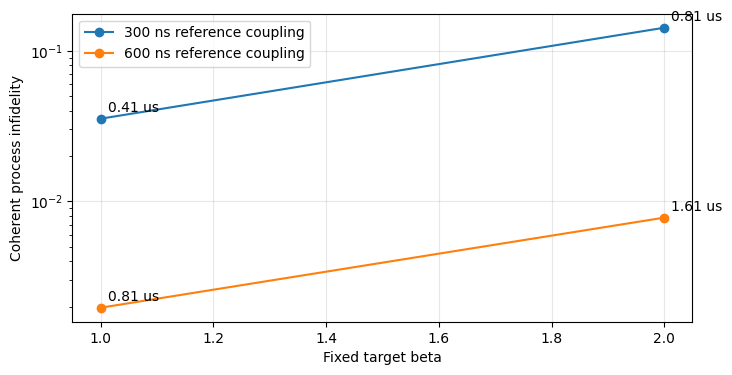

Compared four matched-strength reference gates; all 22 input columns per waveform.


In [2]:
from scipy.optimize import minimize_scalar
from scaled_cd import arrays, target as cd_target, align_z
import hardware_check as hw
matched=[]
for swap,cells,beta in [(.6,16,1.),(.6,32,2.),(.3,8,1.),(.3,16,2.)]:
    reference=dict(job=dict(gate='cd',strength=beta,swap=swap,cells=cells,gap=.020),
                   qubit_phases=np.resize([0.,0.,np.pi,np.pi],cells).tolist(),
                   pump_phases=np.full(cells,-np.pi/2).tolist(),qubit_frame_Rz=0.)
    space,initial,desired=cd_target(beta,96);evaluations=[]
    def cost(gain):
        q,s,words=arrays(reference,gain)
        out=hw.propagate(q,s,initial,cd.DT/8,order=8,fast=True)
        zeta=align_z(out,desired);out*=np.exp(-1j*zeta*space.z/2)[:,None]
        F=float(abs(np.vdot(desired,out)/22)**2)
        evaluations.append(dict(swap_ns=swap*1000,beta=beta,pi_pulses=cells,pump_gain=gain,
                                F=F,error=1-F,time_us=len(words['qubit'])*cd.DT))
        return 1-F
    minimize_scalar(cost,bounds=(.65,1.3),method='bounded',options=dict(xatol=1e-5,maxiter=35))
    matched.append(max(evaluations,key=lambda r:r['F']))
native=pd.DataFrame(matched);native['beta_per_us']=native.beta/native.time_us
assert len(native)==4
display(native)
fig,ax=plt.subplots(figsize=(8,4))
for swap,group in native.groupby('swap_ns'):
    ax.plot(group.beta,group.error,'o-',label=f'{swap:g} ns reference coupling')
    for _,r in group.iterrows():ax.annotate(f'{r.time_us:.2f} us',(r.beta,r.error),xytext=(5,5),textcoords='offset points')
ax.set(xlabel='Fixed target beta',ylabel='Coherent process infidelity',yscale='log')
ax.grid(alpha=.3);ax.legend();plt.show()
print('Compared four matched-strength reference gates; all 22 input columns per waveform.')

## 3. What the optimizer changes

For every fixed (beta, swap, integer N, sampled gap), the original L-BFGS-B search changes qubit phases and pump phases. Qubit envelopes remain 30 ns pi pulses and the pump magnitude is fixed. It uses an exact gradient of the unfiltered cell model, then holds the resulting common qubit Z fixed for final replay. The saved 696 searches include today's four-pulse pattern and three random starts at each tested point. `free`, tied `palindrome`, and `qubit only` are different parameter maps, not different target gates.

The original search is a design surrogate; **all its saved phase lists have now been replayed from the corrected SDK-loaded words through the documented RFDC filter**. The plots below use those replay scores at their recorded search cutoff. Final accepted gates have target/output column convergence and an independent solver check.

A stronger pump magnifies unwanted finite-pulse and higher-order terms. Changing both phases can reduce them. A palindrome of phase labels alone does not establish a Magnus-order theorem for the finite sampled pulse train. Its poorer numerical scores are local search observations; they do not prove that every symmetric CD scheme fails.

**What was found:** selected free-phase trains improve the speed/accuracy tradeoff; a fixed pump phase was less effective in the tested fast cases. These are independently optimized beta=1 and beta=2 gates. Repeating one blindly is not a reliable scaling rule. The reusable motif study later in this notebook explicitly tests shared phases across several strengths and held-out intermediate betas.

696 optimisations, 656,451 evaluations


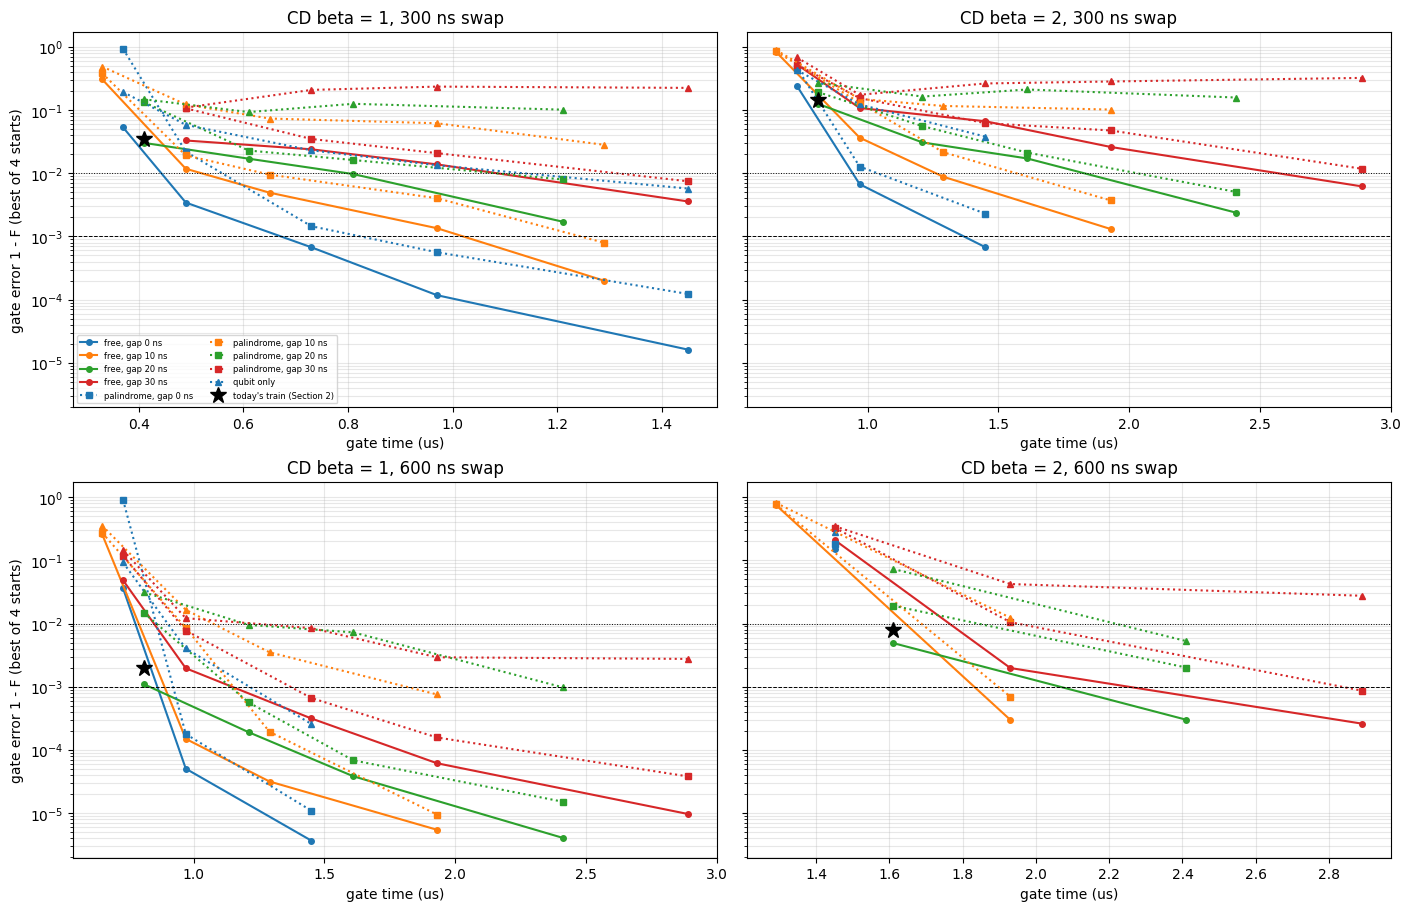

In [3]:
rows = [dict(swap_ns=r["swap_ns"], beta=r["job"]["strength"], kind=r["job"]["kind"], start=r["job"]["start"],
             pi_pulses=r["cells"], gap_ns=r["gap_ns"], time_us=r["time_us"], F=played_cd[result_index], F_design=r["fidelity"], evaluations=r["evaluations"])
        for result_index,r in enumerate(runs)]
alls = pd.DataFrame(rows)
print(f"{len(alls)} optimisations, {alls.evaluations.sum():,} evaluations")
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True, constrained_layout=True)
for row, swap in zip(axes, (300, 600)):
    for ax, beta in zip(row, (1.0, 2.0)):
        d = alls[(alls.swap_ns == swap) & (alls.beta == beta)]
        for kind, marker in (("free", "o"), ("palindrome", "s"), ("qubit only", "^")):
            for gap, colour in ((0, "C0"), (10, "C1"), (20, "C2"), (30, "C3")):
                e = d[(d.kind == kind) & (d.gap_ns == gap)].groupby("time_us").F.max()
                if len(e):
                    ax.plot(e.index, 1 - e.values, marker + ("-" if kind == "free" else ":"), color=colour, ms=4,
                            label=f"{kind}, gap {gap} ns" if kind != "qubit only" else ("qubit only" if gap == 0 else None))
        n = native[(native.swap_ns == swap) & (abs(native.beta - beta) < 0.15)]
        ax.plot(n.time_us, n.error, "k*", ms=12, label="today's train (Section 2)")
        ax.set_yscale("log"); ax.grid(alpha=0.3, which="both")
        ax.axhline(1e-2, color="k", ls=":", lw=0.7); ax.axhline(1e-3, color="k", ls="--", lw=0.7)
        ax.set_title(f"CD beta = {beta:g}, {swap} ns swap"); ax.set_xlabel("gate time (us)")
    row[0].set_ylabel("gate error 1 - F (best of 4 starts)")
axes[0, 0].legend(fontsize=6, ncol=2)
plt.show()

**Reading the search.** The points compare recorded local fits across cell counts, gaps, coupling strengths and phase maps. They are SDK+RFDC replays at the search cutoff, not hardware measurements. Only the final eight chosen gates have the separate enlarged-cutoff certificate. A lower point shows a better observed tradeoff within this grid, not a proof of a minimum gate time.

## 4. The chosen CD gates

All diagrams use physical DAC phases: qubit phase = minus the model phase, pump phase = model phase. The carrier NCO stays fixed. Phase changes are samples in one merged `use_stretch=False` waveform per channel, with one common trigger. The published linear RFDC interpolation rounds those changes; startup and tail are included in propagation. Analog line response and undocumented converter rounding remain outside this ideal two-level model.

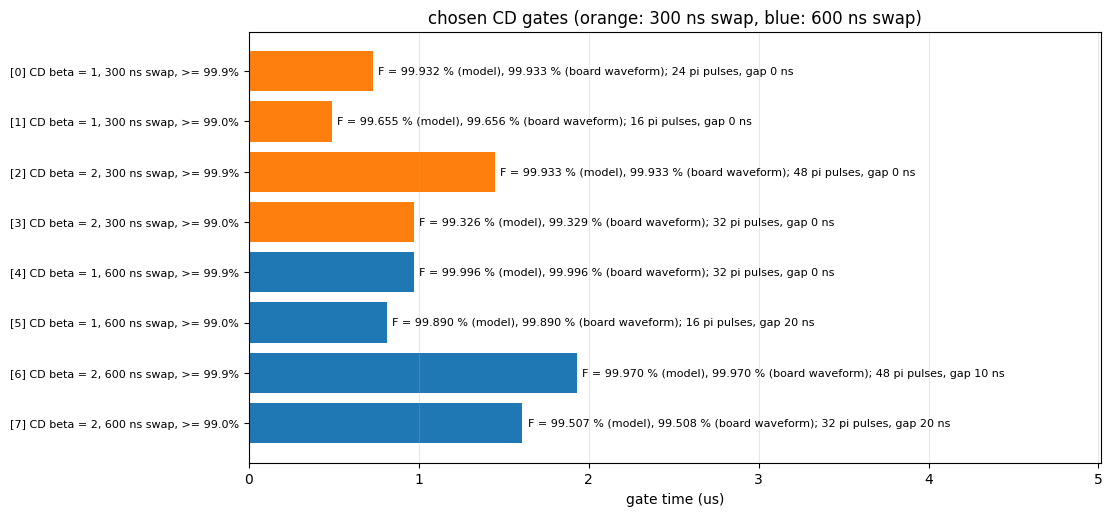

[0] CD beta = 1, 300 ns swap, >= 99.9%: 0.73 us; 64 vs 128 photon levels: F = 0.99932481 vs 0.99932481; board-waveform cutoff 96 levels
[1] CD beta = 1, 300 ns swap, >= 99.0%: 0.49 us; 64 vs 128 photon levels: F = 0.99655427 vs 0.99655427; board-waveform cutoff 96 levels


[2] CD beta = 2, 300 ns swap, >= 99.9%: 1.45 us; 64 vs 128 photon levels: F = 0.99932950 vs 0.99932950; board-waveform cutoff 96 levels
[3] CD beta = 2, 300 ns swap, >= 99.0%: 0.97 us; 64 vs 128 photon levels: F = 0.99325604 vs 0.99325604; board-waveform cutoff 96 levels


[4] CD beta = 1, 600 ns swap, >= 99.9%: 0.97 us; 64 vs 128 photon levels: F = 0.99996159 vs 0.99996159; board-waveform cutoff 96 levels
[5] CD beta = 1, 600 ns swap, >= 99.0%: 0.81 us; 64 vs 128 photon levels: F = 0.99889959 vs 0.99889959; board-waveform cutoff 96 levels


[6] CD beta = 2, 600 ns swap, >= 99.9%: 1.93 us; 64 vs 128 photon levels: F = 0.99970129 vs 0.99970129; board-waveform cutoff 96 levels
[7] CD beta = 2, 600 ns swap, >= 99.0%: 1.61 us; 64 vs 128 photon levels: F = 0.99507250 vs 0.99507250; board-waveform cutoff 96 levels


In [4]:
fig, ax = plt.subplots(figsize=(11, 0.55 * len(final) + 1.2))
for i, r in enumerate(final):
    ax.barh(i, r["time_us"], color="C1" if r["swap_ns"] == 300 else "C0")
    ax.text(r["time_us"] + 0.03, i, f"F = {100 * r['at_128_levels']['fidelity']:.3f} % (model), "
            f"{100 * r['hardware_check']['fidelity']:.3f} % (board waveform); {r['cells']} pi pulses, gap {r['gap_ns']:.0f} ns",
            va="center", fontsize=8)
ax.set_yticks(range(len(final)), [f"[{i}] {r['job']['label']}" for i, r in enumerate(final)], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("gate time (us)"); ax.grid(alpha=0.3, axis="x")
ax.set_xlim(0, max(r["time_us"] for r in final) * 2.6)
ax.set_title("chosen CD gates (orange: 300 ns swap, blue: 600 ns swap)")
plt.show()
for i, r in enumerate(final):
    tr = train_of(r)
    print(f"[{i}] {r['job']['label']}: {r['time_us']:.2f} us; 64 vs 128 photon levels: F = {tr.report(controls_of(r))['fidelity']:.8f} vs "
          f"{r['at_128_levels']['fidelity']:.8f}; board-waveform cutoff {r['hardware_check']['levels']} levels")

### [0] CD β = 1, 300 ns swap, 0.73 µs, 99.932 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 1, 300 ns swap, >= 99.9%: 24 pi pulses, gap 0 ns, 0.73 us
Found: random 0 start (F = 0.999325), polished with 3 more evaluations -> F = 0.999325; board waveform 0.999326; worst single input 0.99782; after the gate: qubit Rz(-5.82399 rad)


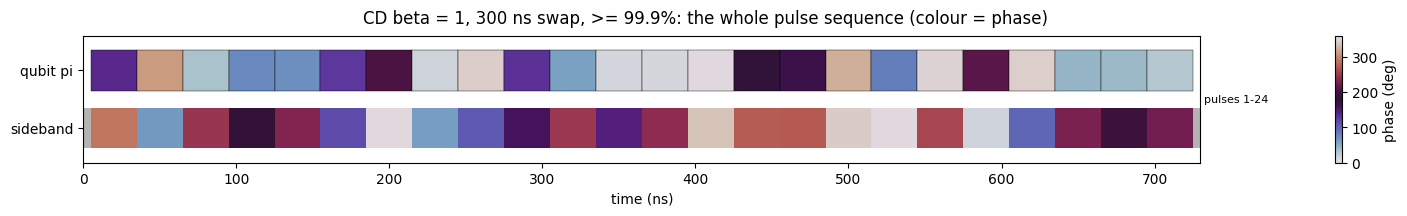

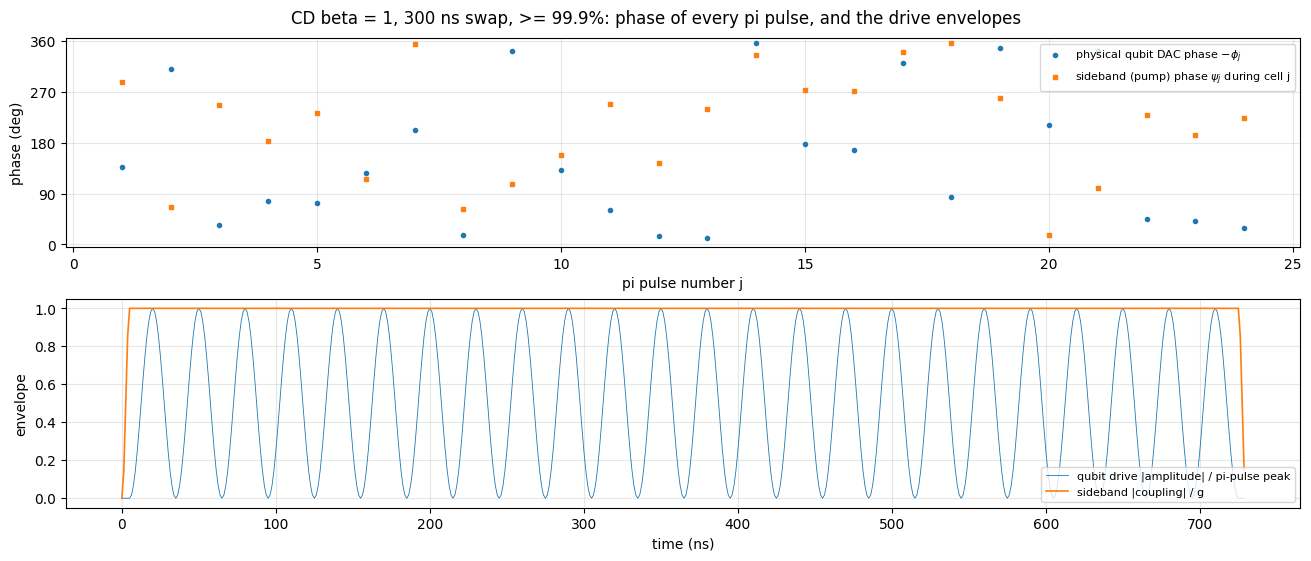

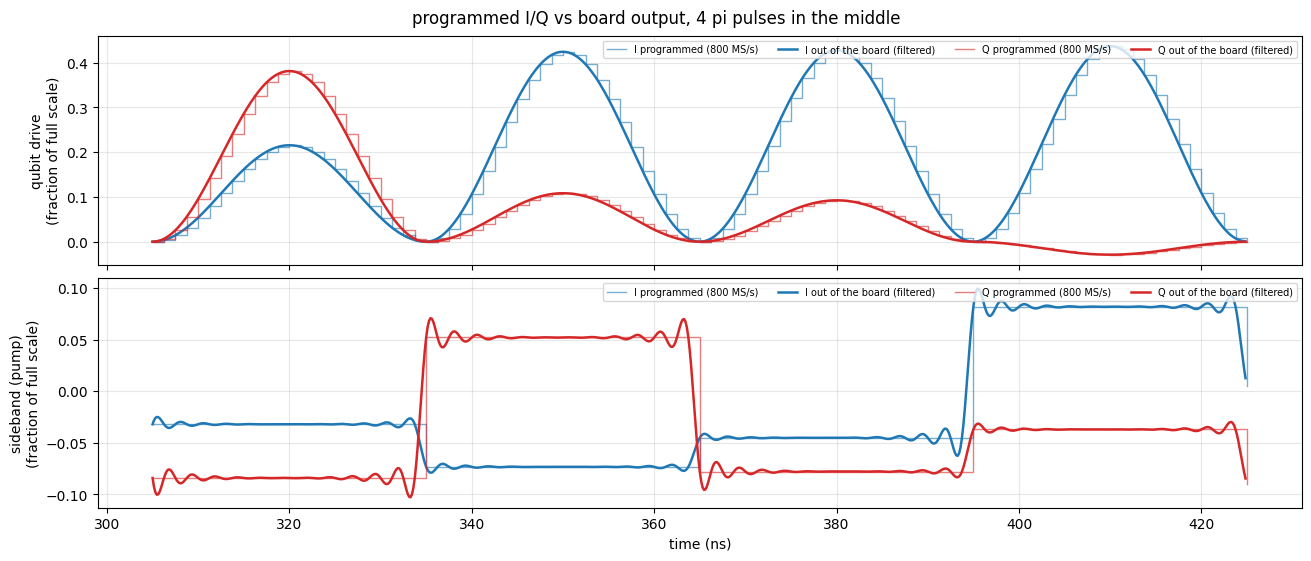

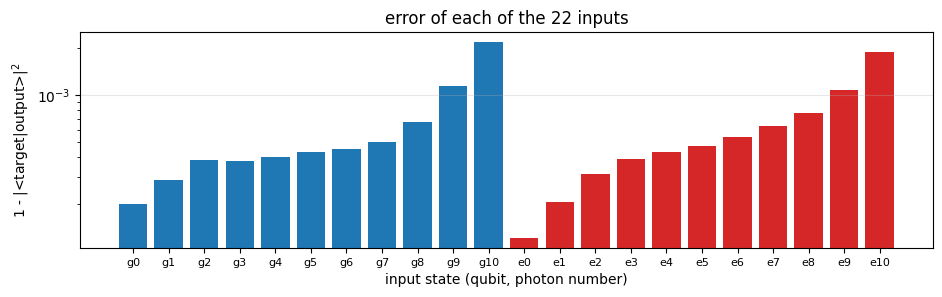

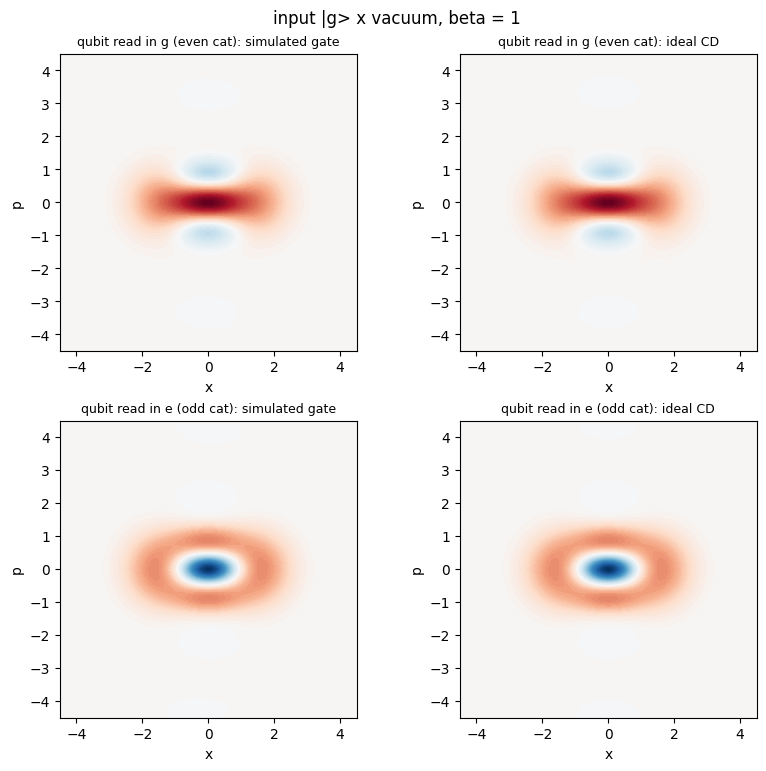

sequence for programming: runs/cd_sequence_0.csv; int16 I/Q words: runs/cd_words_0.npz


In [5]:
result = final[0]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{0}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{0}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [1] CD β = 1, 300 ns swap, 0.49 µs, 99.655 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 1, 300 ns swap, >= 99.0%: 16 pi pulses, gap 0 ns, 0.49 us
Found: native start (F = 0.996554), polished with 3 more evaluations -> F = 0.996554; board waveform 0.996562; worst single input 0.98772; after the gate: qubit Rz(3.37728 rad)


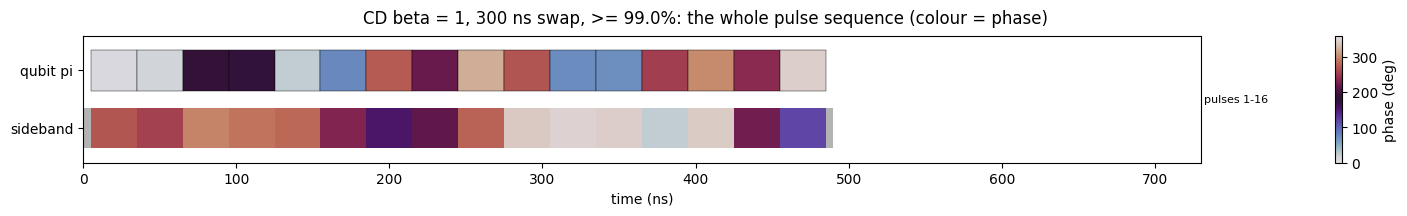

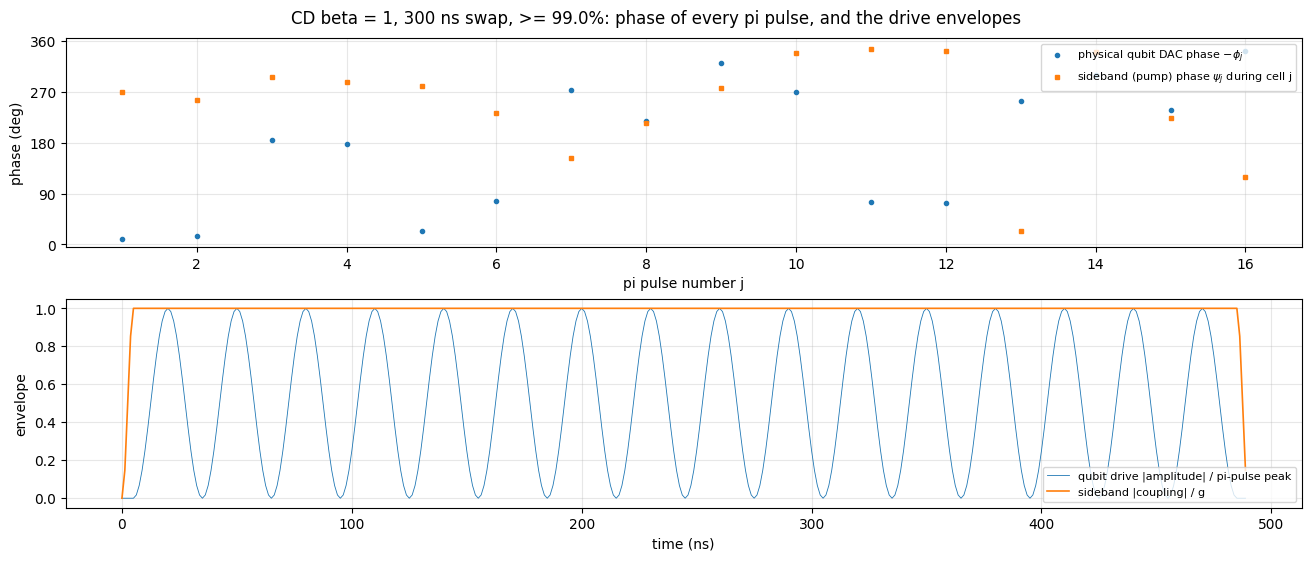

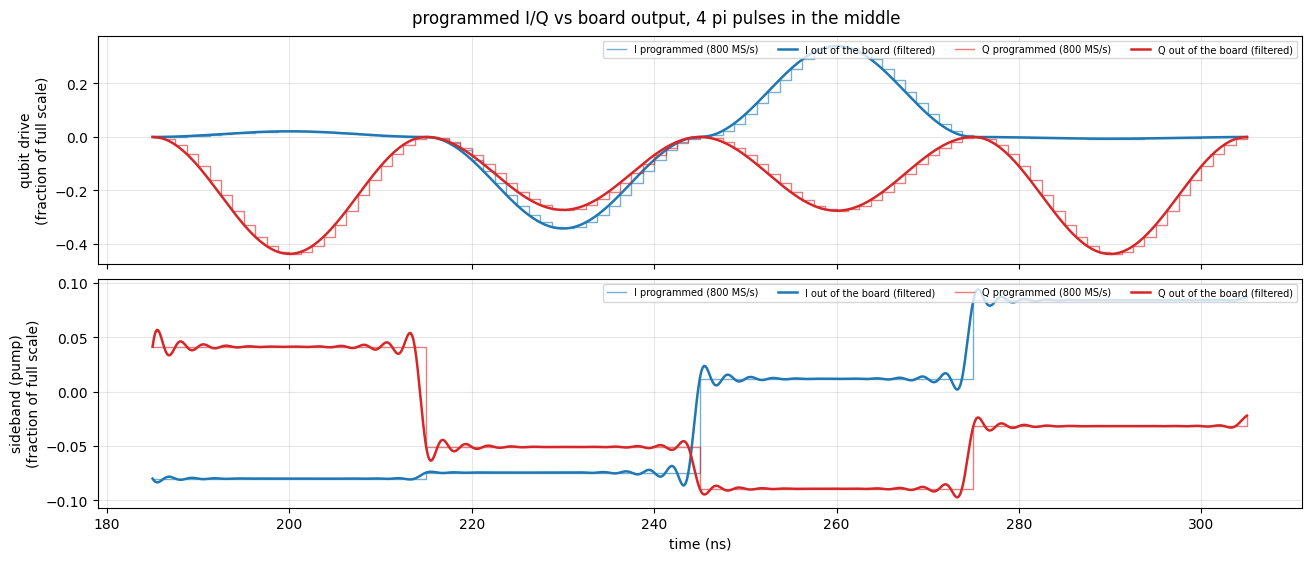

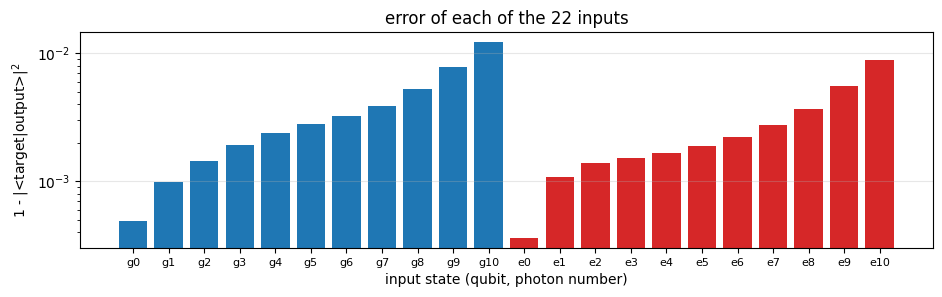

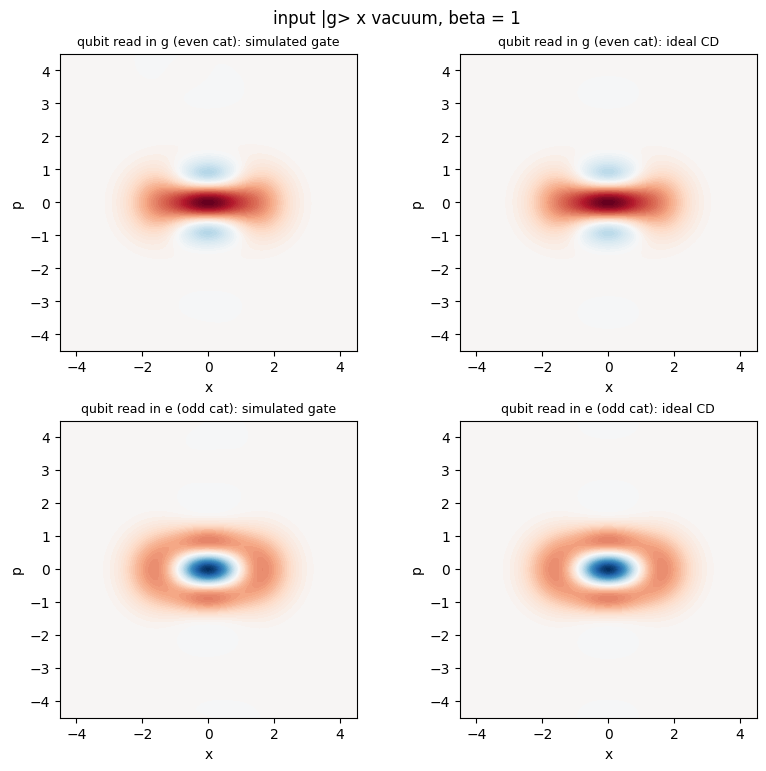

sequence for programming: runs/cd_sequence_1.csv; int16 I/Q words: runs/cd_words_1.npz


In [6]:
result = final[1]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{1}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{1}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [2] CD β = 2, 300 ns swap, 1.45 µs, 99.933 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 2, 300 ns swap, >= 99.9%: 48 pi pulses, gap 0 ns, 1.45 us
Found: random 2 start (F = 0.999319), polished with 9778 more evaluations -> F = 0.999329; board waveform 0.999332; worst single input 0.99728; after the gate: qubit Rz(-4.28250 rad)


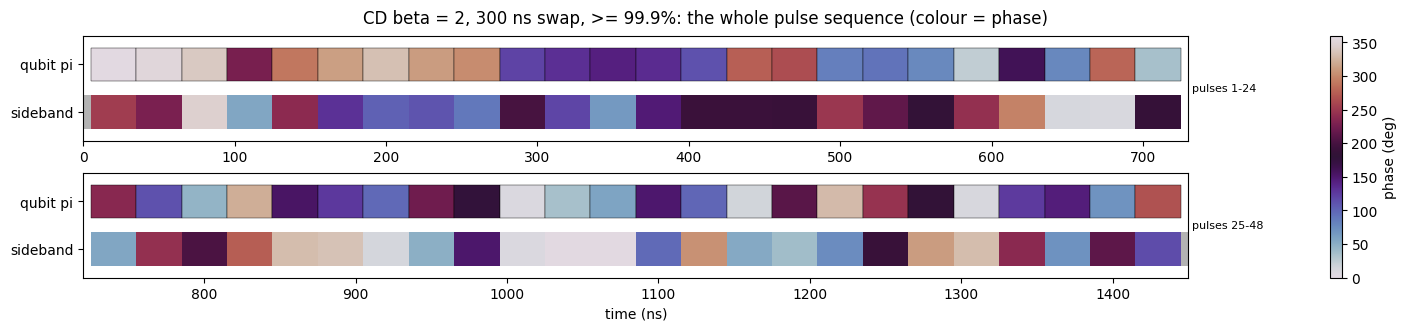

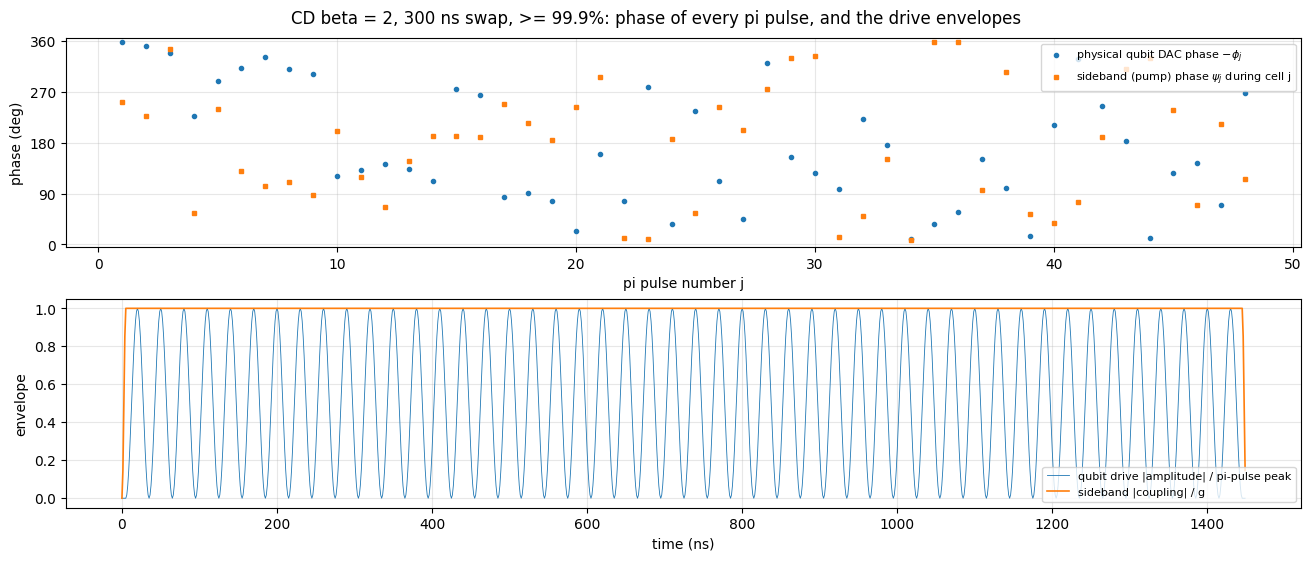

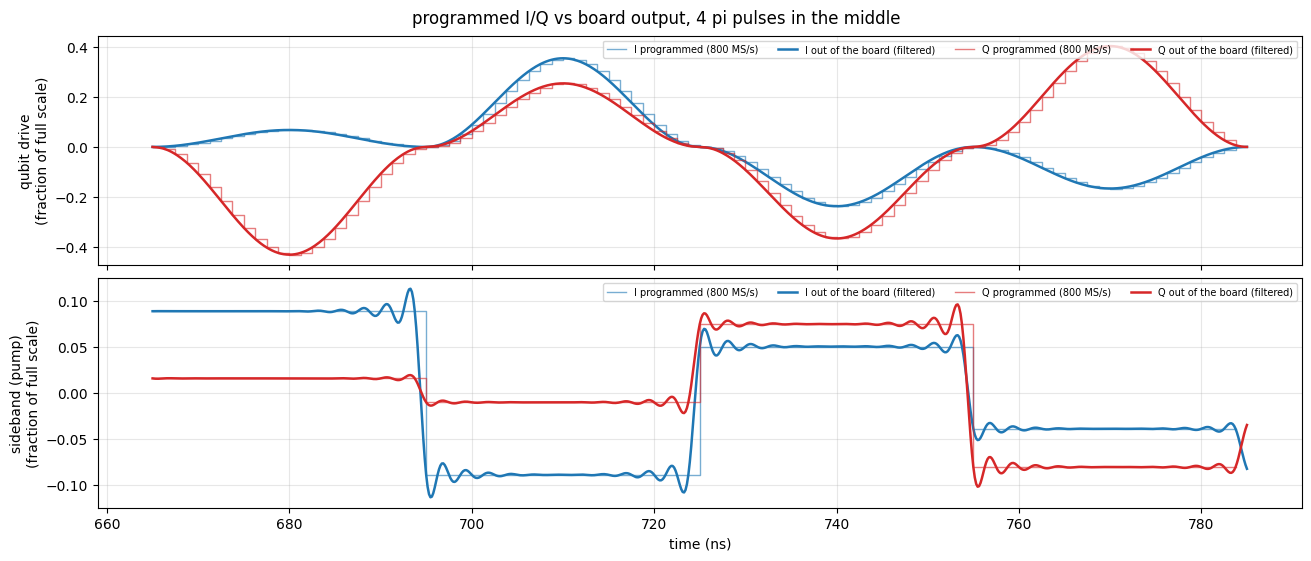

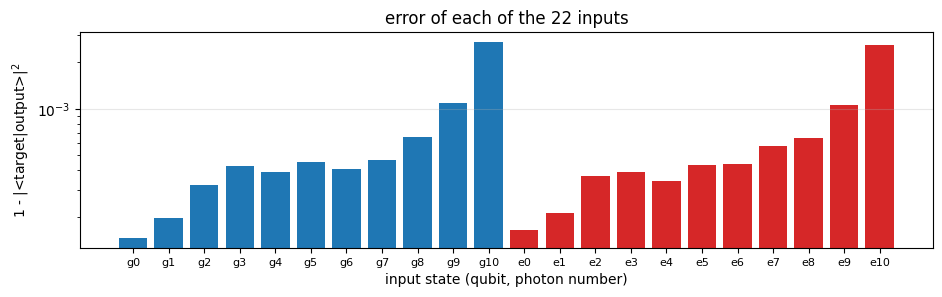

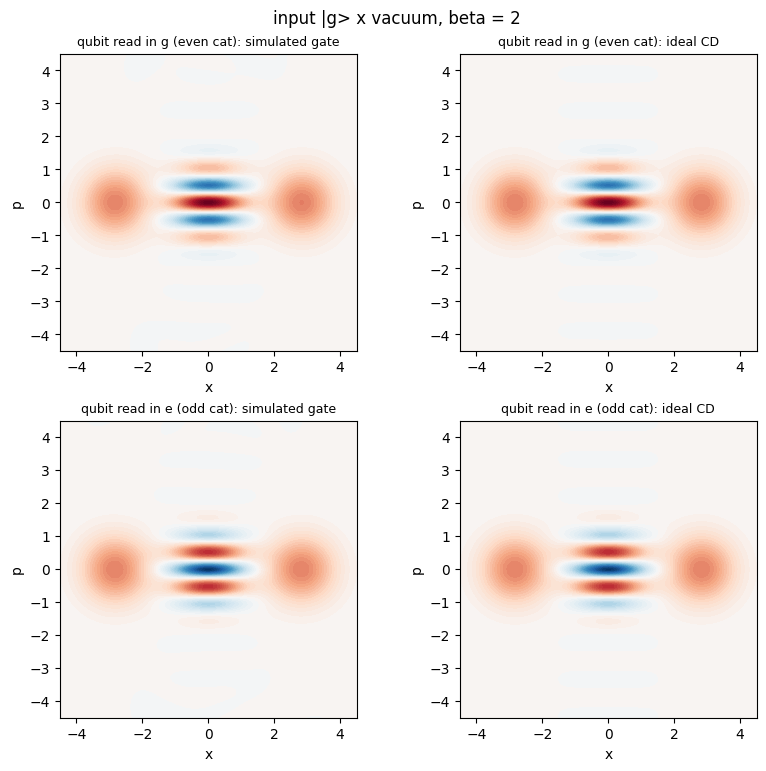

sequence for programming: runs/cd_sequence_2.csv; int16 I/Q words: runs/cd_words_2.npz


In [7]:
result = final[2]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{2}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{2}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [3] CD β = 2, 300 ns swap, 0.97 µs, 99.326 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 2, 300 ns swap, >= 99.0%: 32 pi pulses, gap 0 ns, 0.97 us
Found: native start (F = 0.993256), polished with 3 more evaluations -> F = 0.993256; board waveform 0.993288; worst single input 0.97766; after the gate: qubit Rz(5.09547 rad)


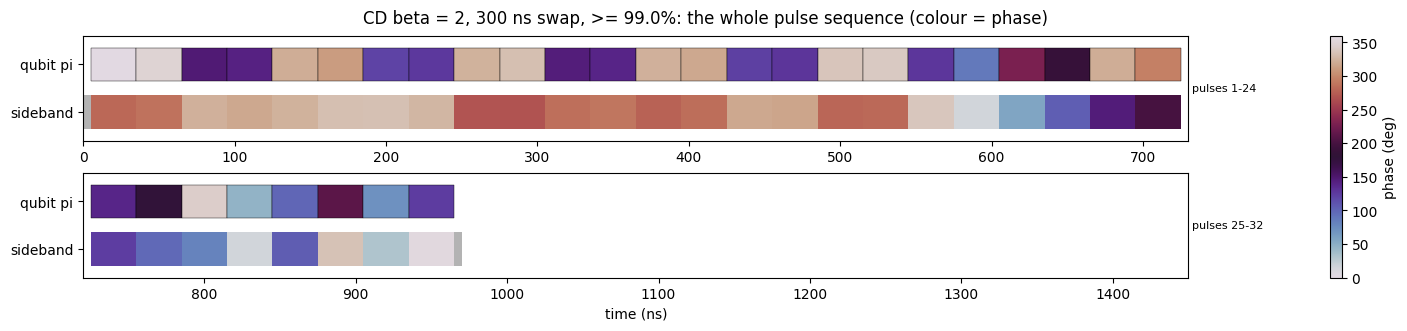

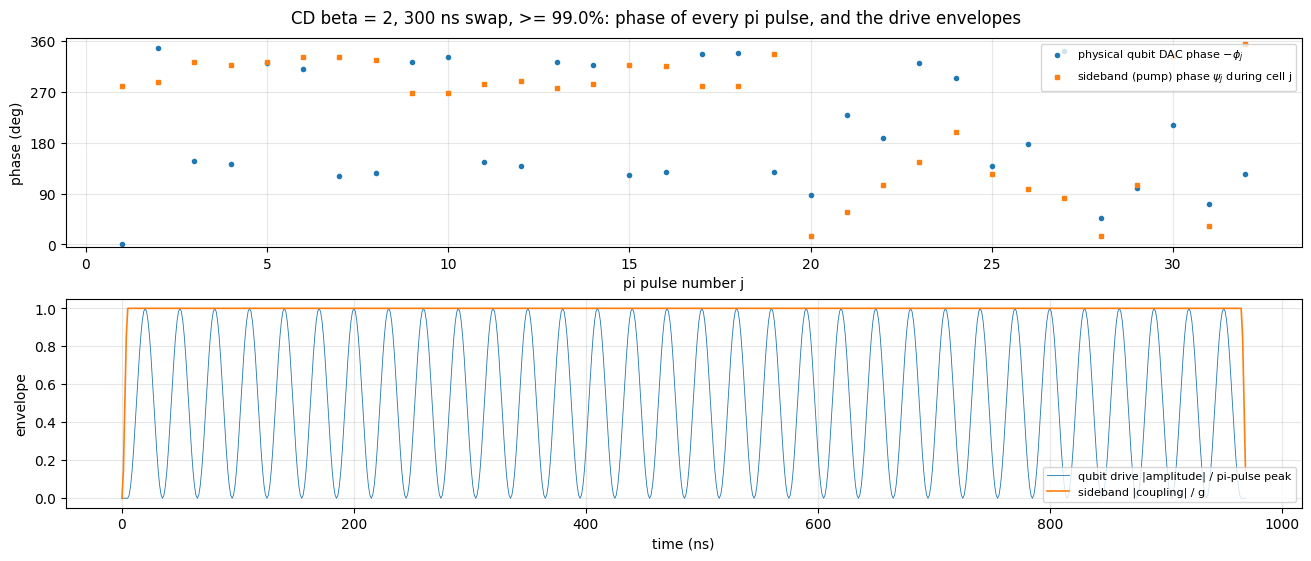

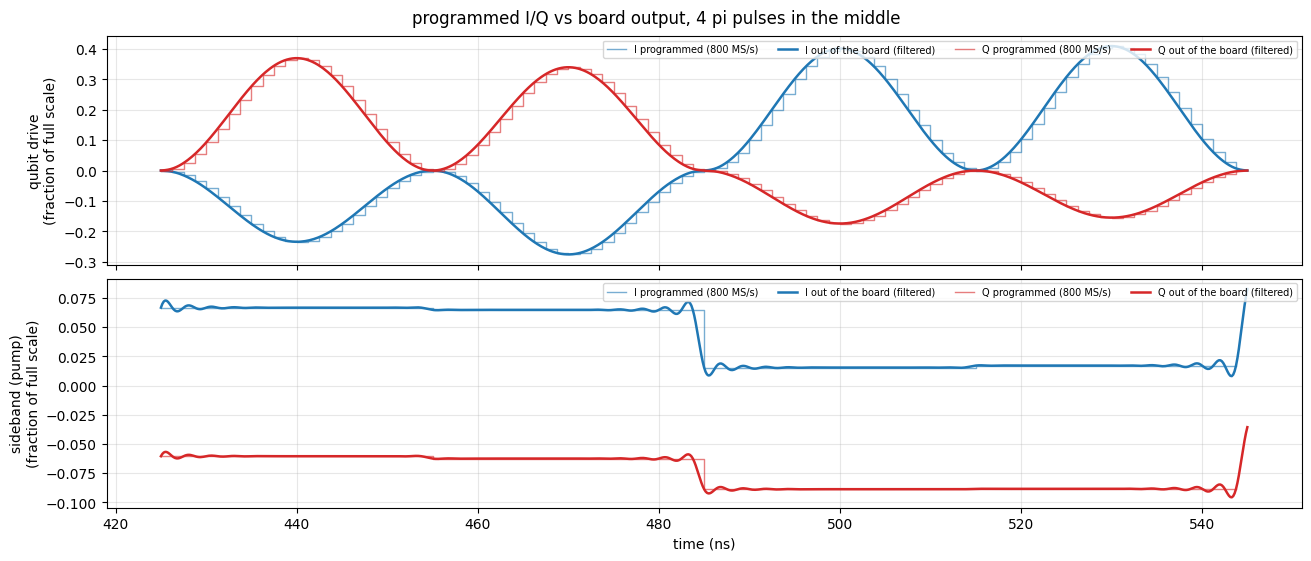

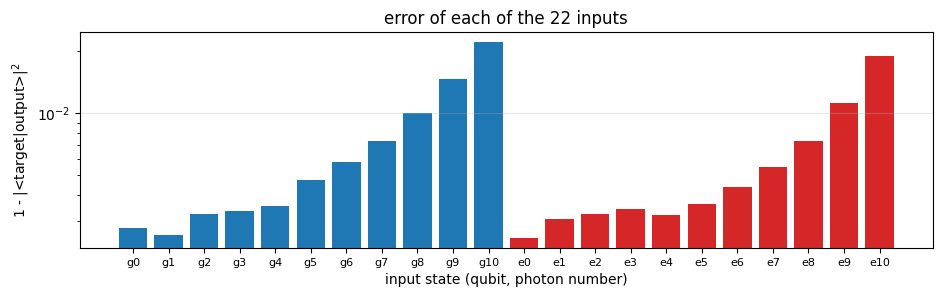

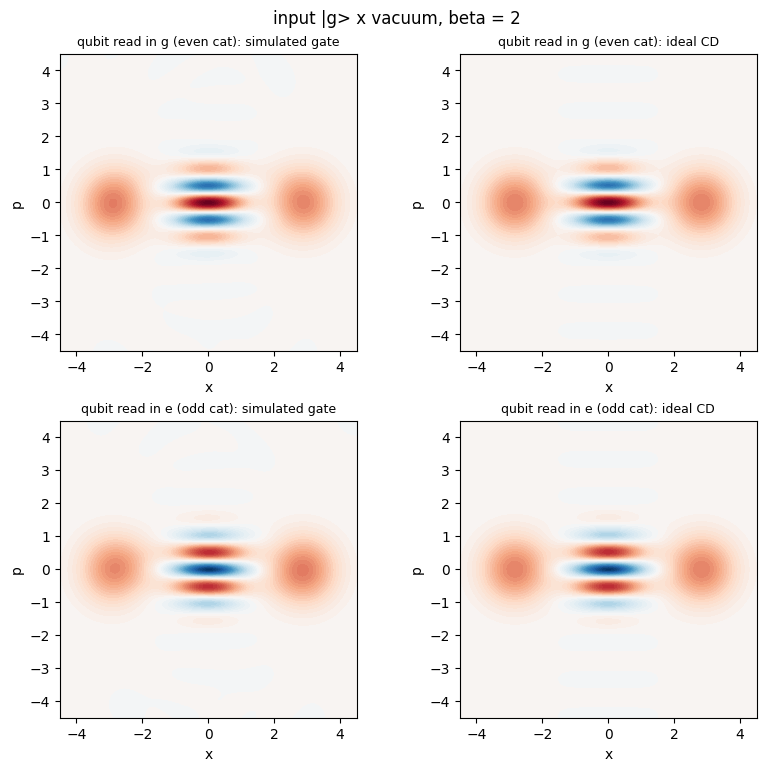

sequence for programming: runs/cd_sequence_3.csv; int16 I/Q words: runs/cd_words_3.npz


In [8]:
result = final[3]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{3}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{3}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [4] CD β = 1, 600 ns swap, 0.97 µs, 99.996 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 1, 600 ns swap, >= 99.9%: 32 pi pulses, gap 0 ns, 0.97 us
Found: native start (F = 0.999949), polished with 10773 more evaluations -> F = 0.999962; board waveform 0.999962; worst single input 0.99987; after the gate: qubit Rz(0.02779 rad)


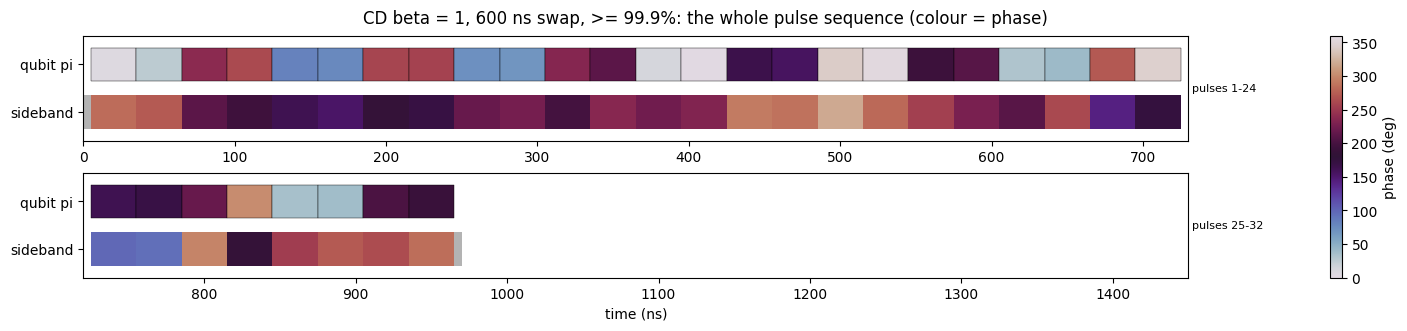

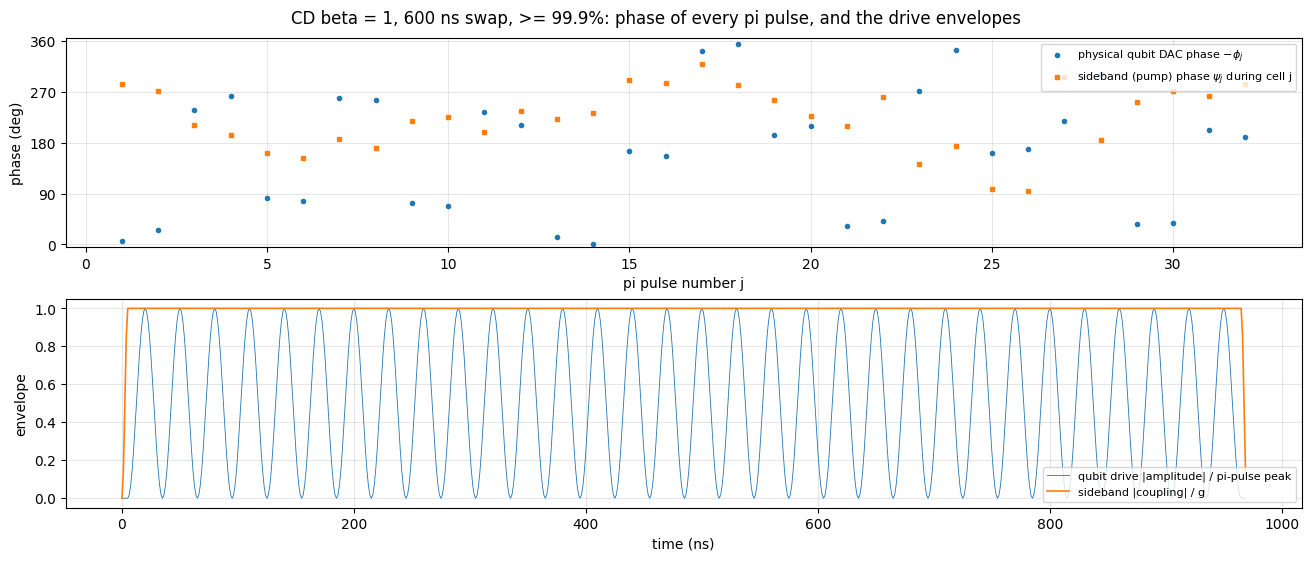

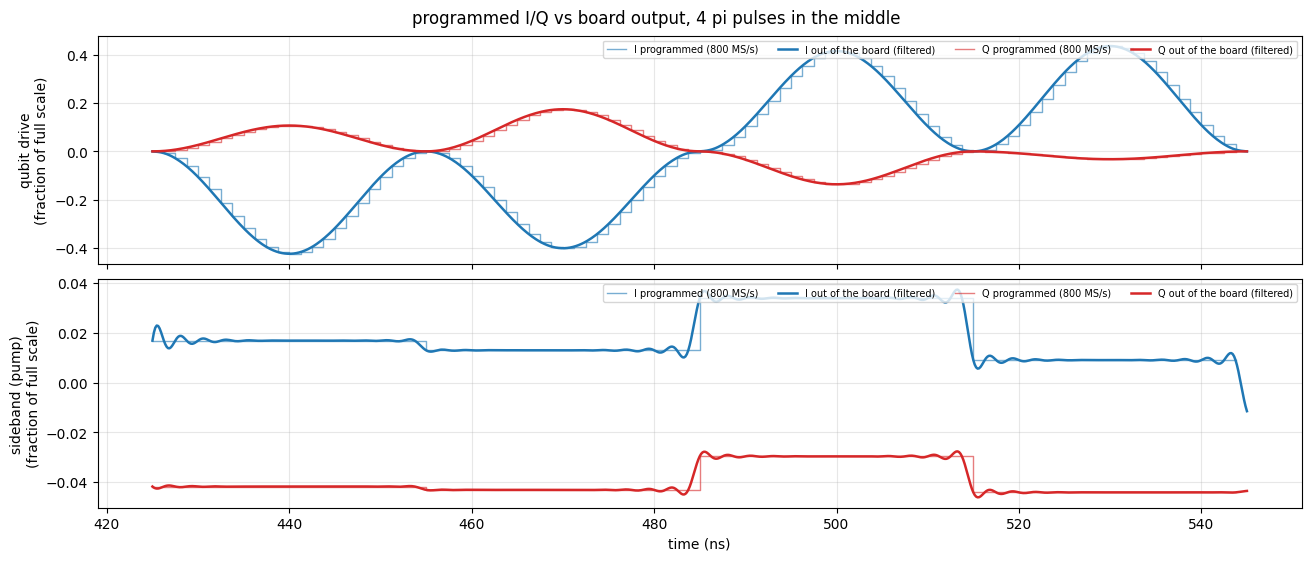

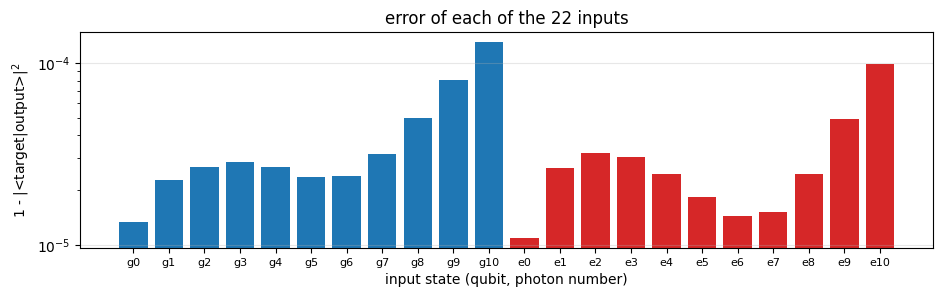

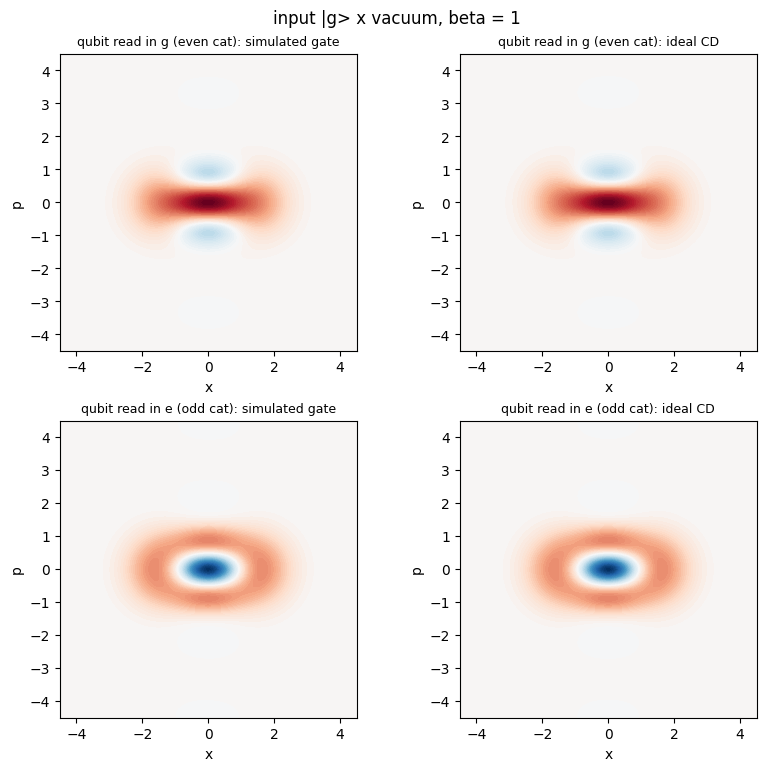

sequence for programming: runs/cd_sequence_4.csv; int16 I/Q words: runs/cd_words_4.npz


In [9]:
result = final[4]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{4}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{4}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [5] CD β = 1, 600 ns swap, 0.81 µs, 99.890 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 1, 600 ns swap, >= 99.0%: 16 pi pulses, gap 20 ns, 0.81 us
Found: native start (F = 0.998900), polished with 3 more evaluations -> F = 0.998900; board waveform 0.998902; worst single input 0.99652; after the gate: qubit Rz(0.59633 rad)


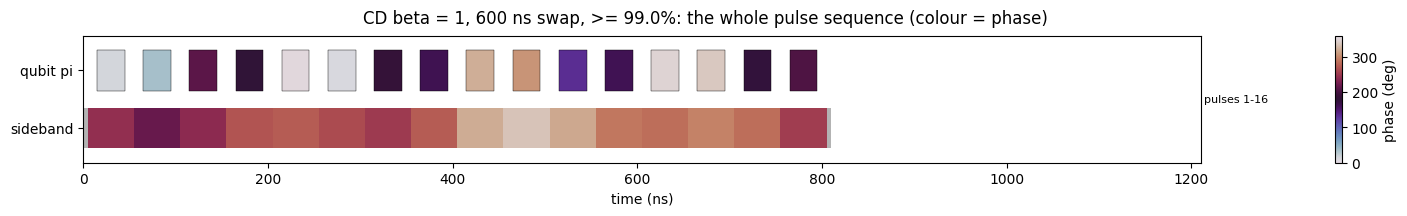

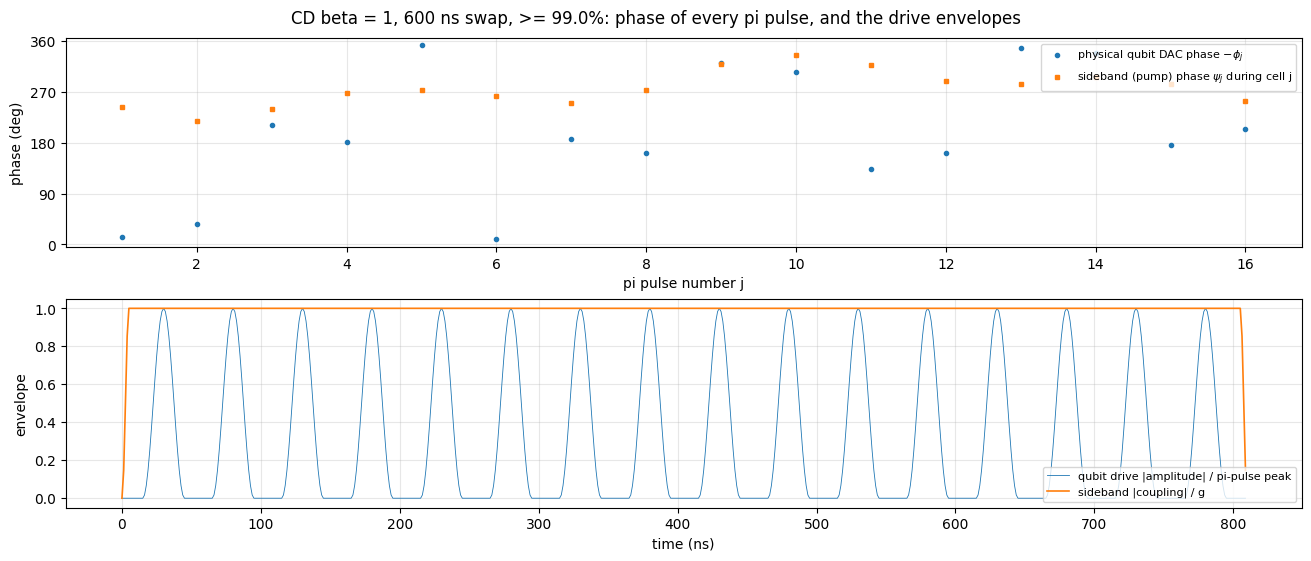

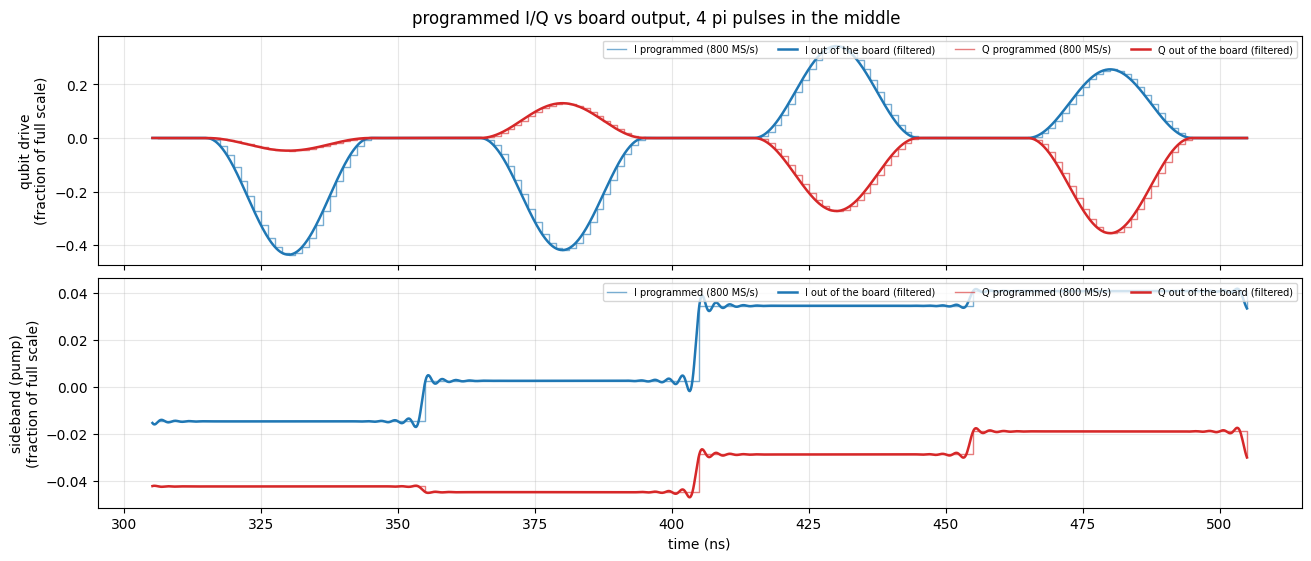

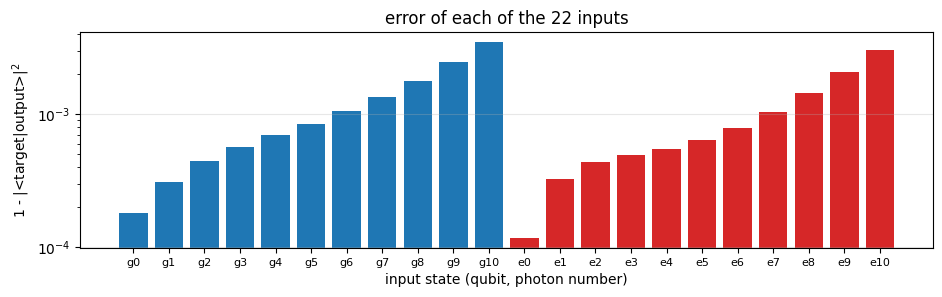

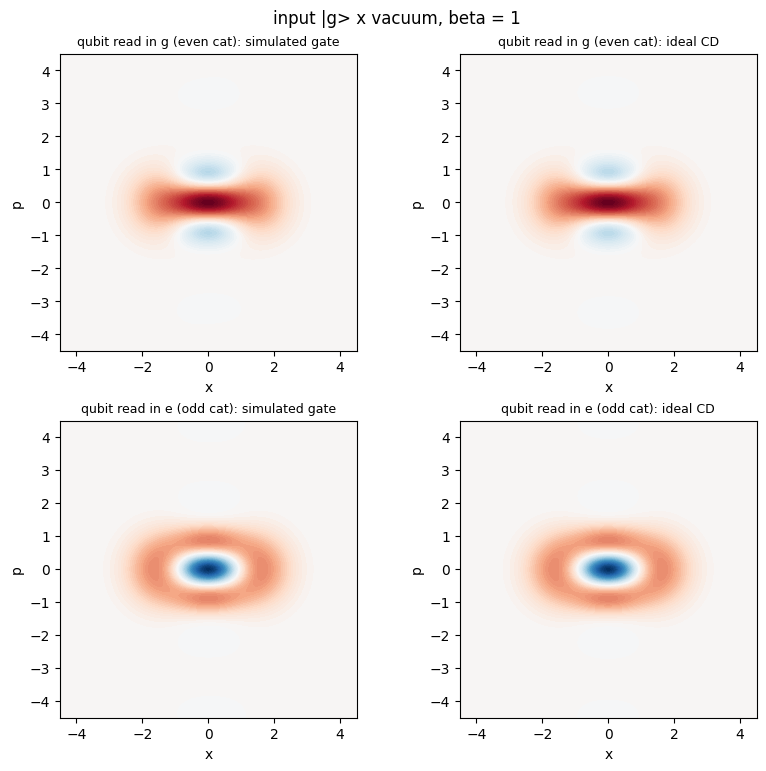

sequence for programming: runs/cd_sequence_5.csv; int16 I/Q words: runs/cd_words_5.npz


In [10]:
result = final[5]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{5}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{5}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [6] CD β = 2, 600 ns swap, 1.93 µs, 99.970 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 2, 600 ns swap, >= 99.9%: 48 pi pulses, gap 10 ns, 1.93 us
Found: native start (F = 0.999699), polished with 10664 more evaluations -> F = 0.999701; board waveform 0.999702; worst single input 0.99903; after the gate: qubit Rz(-5.72887 rad)


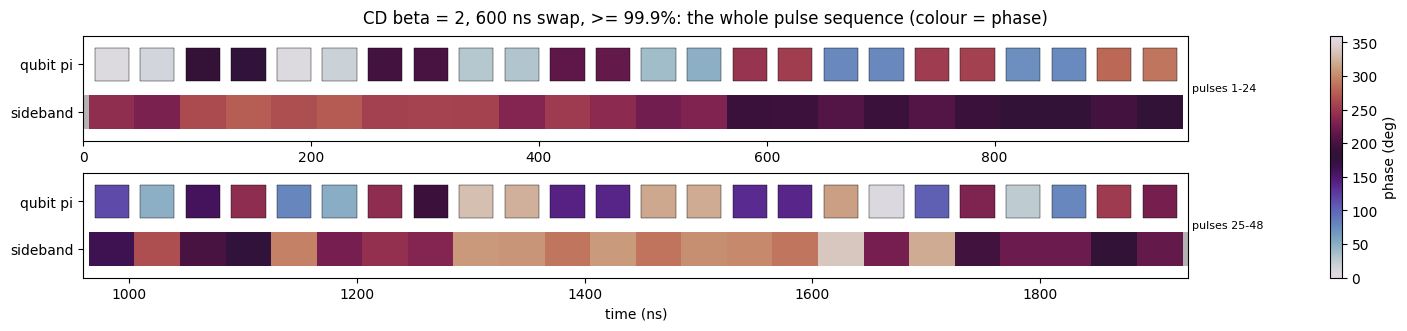

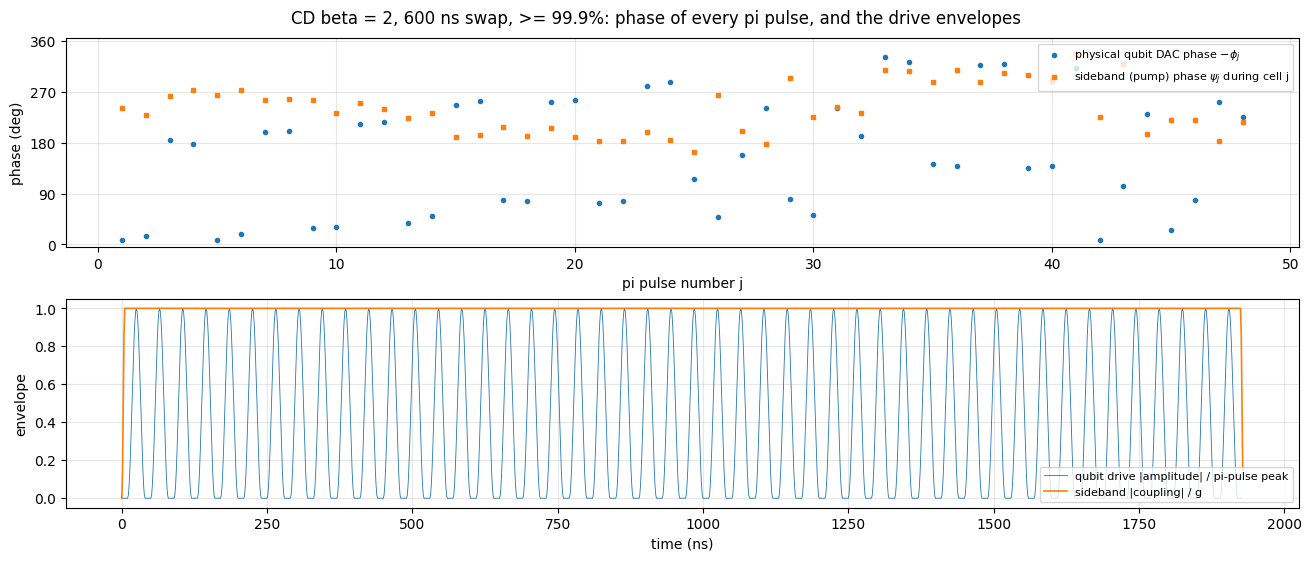

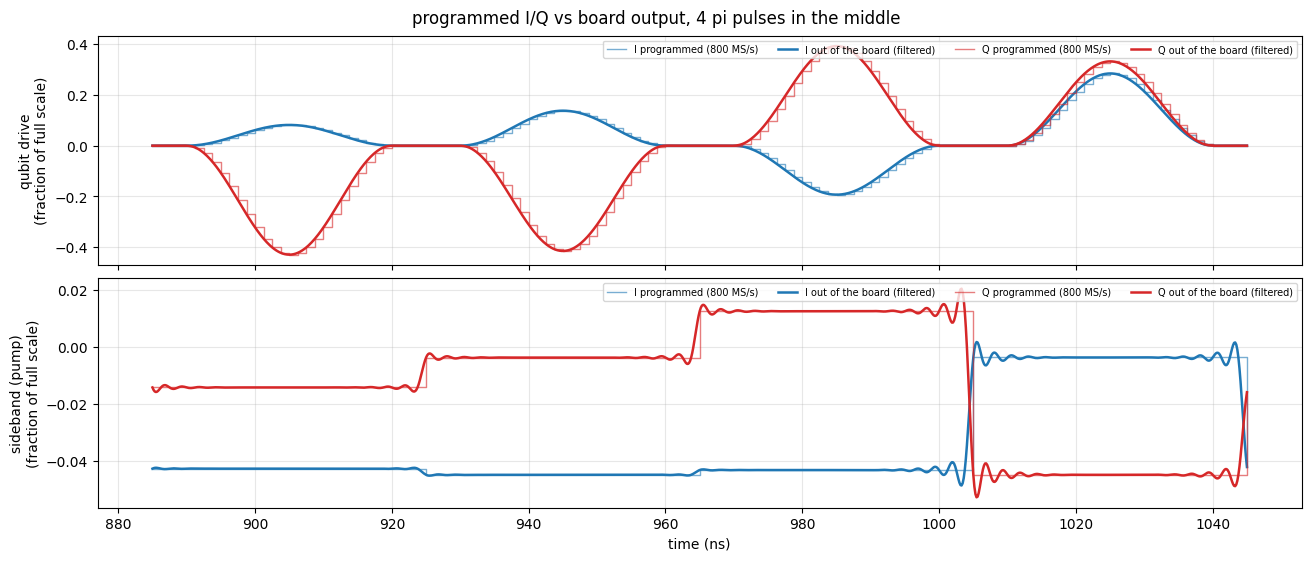

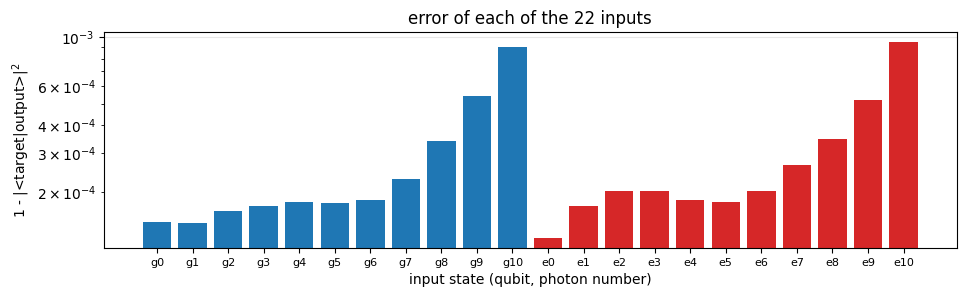

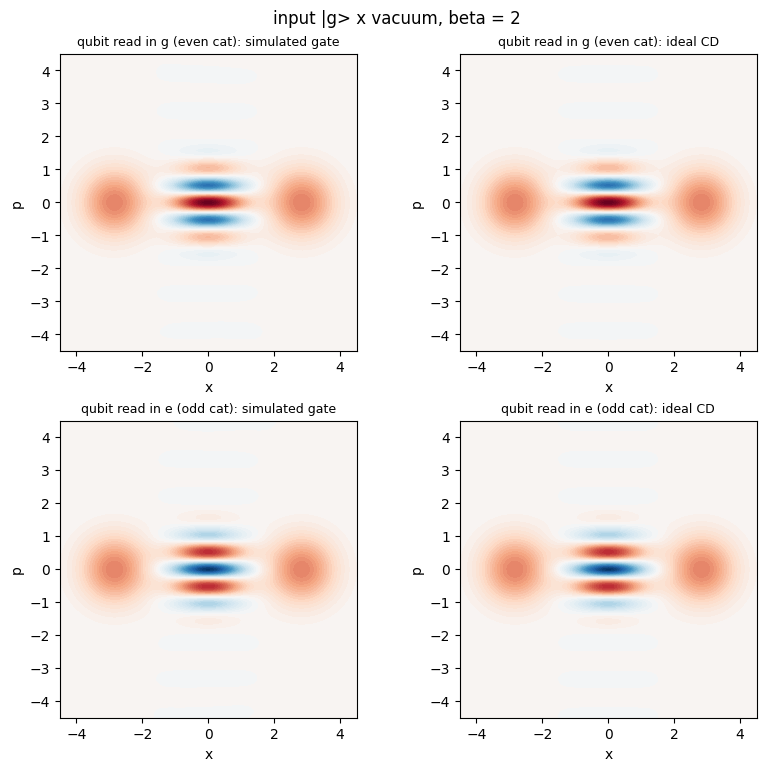

sequence for programming: runs/cd_sequence_6.csv; int16 I/Q words: runs/cd_words_6.npz


In [11]:
result = final[6]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{6}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{6}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

### [7] CD β = 2, 600 ns swap, 1.61 µs, 99.507 %

Figures: the whole pulse sequence (qubit π pulses on top, sideband cells below, colour = phase); the phase of every pulse; programmed I/Q against board output; the error of each of the 22 inputs; and the cat states the gate makes from |g⟩ ⊗ vacuum when the qubit is read in g or e, simulated against ideal.

CD beta = 2, 600 ns swap, >= 99.0%: 32 pi pulses, gap 20 ns, 1.61 us
Found: native start (F = 0.995073), polished with 3 more evaluations -> F = 0.995073; board waveform 0.995082; worst single input 0.98388; after the gate: qubit Rz(0.05254 rad)


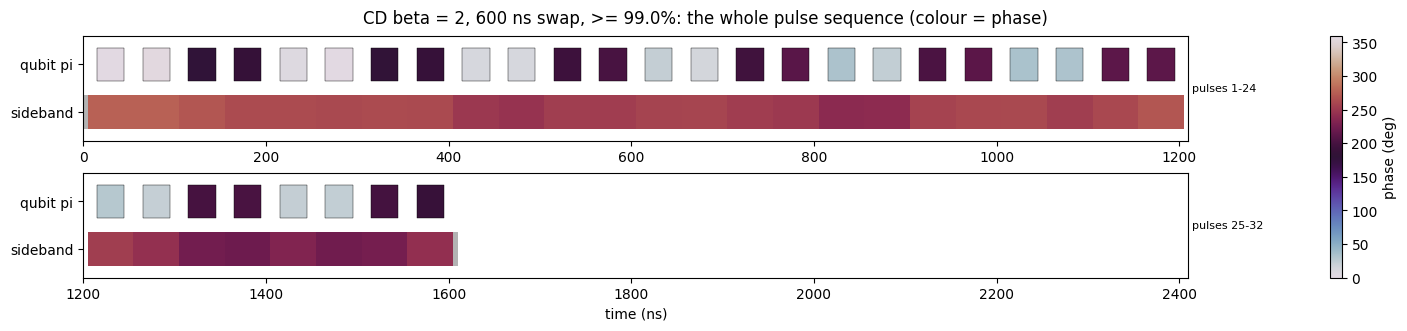

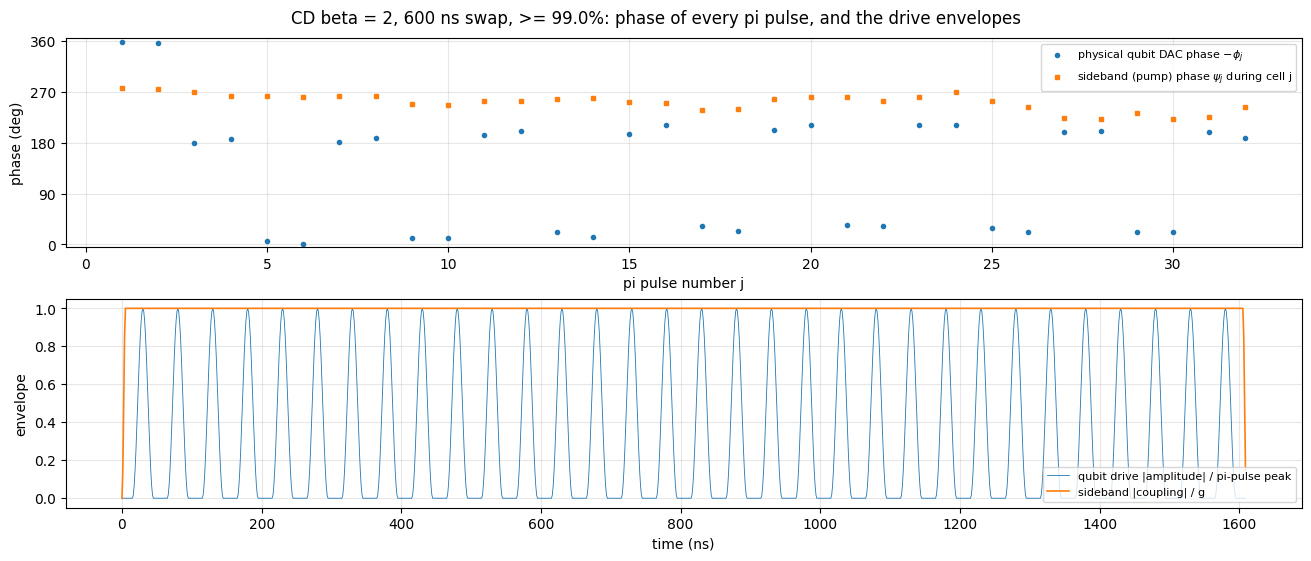

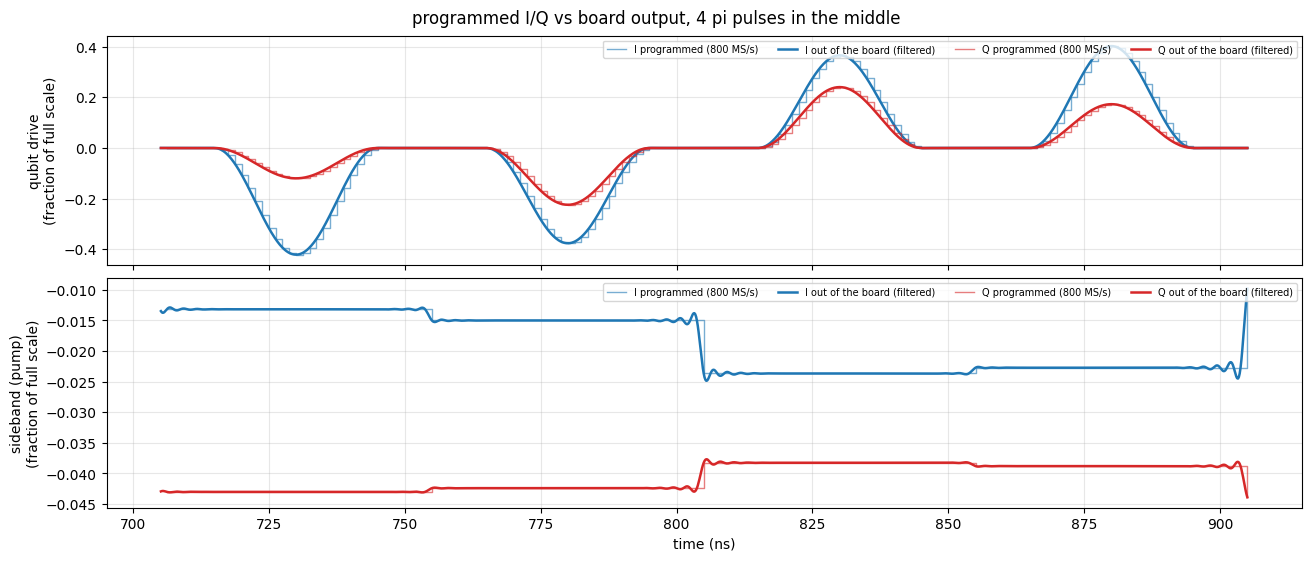

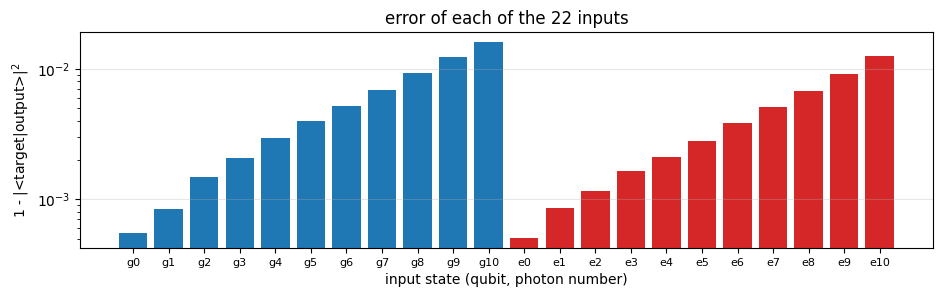

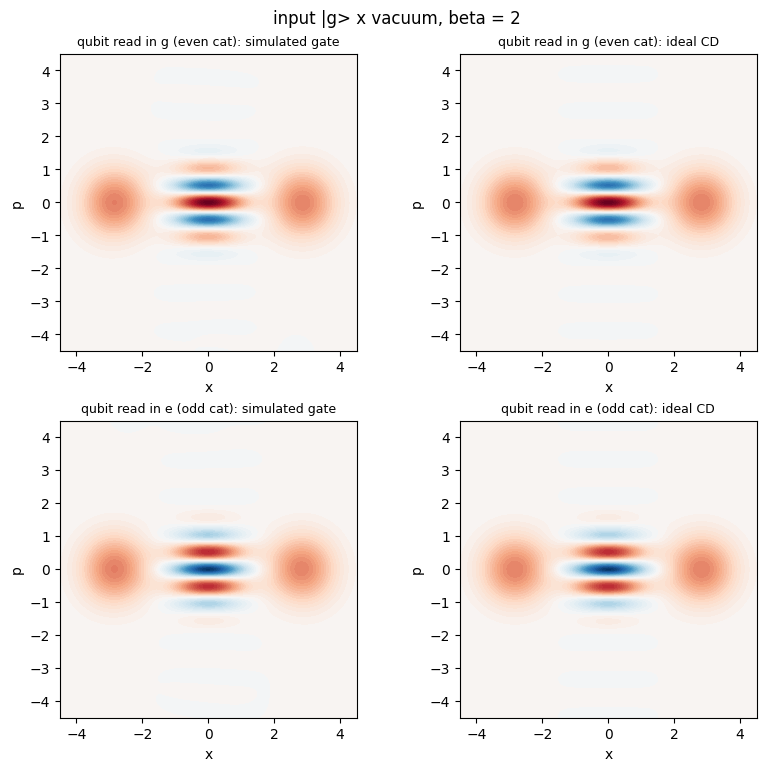

sequence for programming: runs/cd_sequence_7.csv; int16 I/Q words: runs/cd_words_7.npz


In [12]:
result = final[7]
tr, x = train_of(result), controls_of(result)
job = result["job"]
print(f"{job['label']}: {result['cells']} pi pulses, gap {result['gap_ns']:.0f} ns, {result['time_us']:.2f} us")
print(f"Found: {job['found_start']} start (F = {job['found_fidelity']:.6f}), polished with {result['evaluations']} more "
      f"evaluations -> F = {result['fidelity']:.6f}; board waveform {result['hardware_check']['fidelity']:.6f}; "
      f"worst single input {result['at_128_levels']['worst_input_fidelity']:.5f}; after the gate: qubit Rz({result['qubit_frame_Rz']:.5f} rad)")
cp.pulse_diagram(tr, x, f"{job['label']}: the whole pulse sequence (colour = phase)", per_row=24)
cp.sequence_plot(tr, x, f"{job['label']}: phase of every pi pulse, and the drive envelopes")
cp.iq_plot(tr, x, start_pulse=max(0, result["cells"] // 2 - 2), n_pulses=4, title="programmed I/Q vs board output, 4 pi pulses in the middle")

out = cp.played_state(tr, x, tr.inputs, result['qubit_frame_Rz']); frame = 1.
overlaps = np.sum(np.conj(tr.target) * frame * out, axis=0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(tr.d), 1 - abs(overlaps) ** 2, color=["C0"] * N_INPUT + ["C3"] * N_INPUT)
ax.set_xticks(range(tr.d), [f"g{n}" for n in range(N_INPUT)] + [f"e{n}" for n in range(N_INPUT)], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("1 - |<target|output>|$^2$"); ax.set_xlabel("input state (qubit, photon number)")
ax.set_title("error of each of the 22 inputs"); ax.grid(alpha=0.3, axis="y"); plt.show()

# cat states: input |g> x vacuum; read the qubit in g or e -> even / odd cat
psi = np.zeros(2 * tr.space.levels, complex); psi[0] = 1
out_state = cp.played_state(tr, x, psi, result['qubit_frame_Rz'])
ideal = tr.target[:, 0]
grid = np.linspace(-4.5, 4.5, 181)
fig, axes = plt.subplots(2, 2, figsize=(8, 7.6), constrained_layout=True)
for row, (branch, rows_) in enumerate((("g (even cat)", slice(0, None, 2)), ("e (odd cat)", slice(1, None, 2)))):
    for col, (label, vec) in enumerate((("simulated gate", out_state), ("ideal CD", ideal))):
        ket = vec[rows_]; ket = ket / np.linalg.norm(ket)
        W = cp.qt.wigner(cp.qt.Qobj(ket[:, None]), grid, grid)
        axes[row, col].contourf(grid, grid, W, 60, cmap="RdBu_r", vmin=-1 / np.pi, vmax=1 / np.pi)
        axes[row, col].set_aspect("equal"); axes[row, col].set_xlabel("x"); axes[row, col].set_ylabel("p")
        axes[row, col].set_title(f"qubit read in {branch}: {label}", fontsize=9)
fig.suptitle(f"input |g> x vacuum, beta = {job['strength']:g}"); plt.show()
pd.DataFrame(dict(pulse=np.arange(1, result["cells"] + 1), qubit_DAC_phase_deg=np.degrees(-x[:result["cells"]]) % 360,
                  qubit_Hamiltonian_phase_deg=np.degrees(x[:result["cells"]]) % 360,
                  pump_phase_deg=np.degrees(x[result["cells"]:]) % 360)).to_csv(f"{RUNS}/cd_sequence_{7}.csv", index=False)
print(f"sequence for programming: {RUNS}/cd_sequence_{7}.csv; int16 I/Q words: {RUNS}/{result['words_file']}")

## 5. What these fixed-strength searches establish

The beta=1 and beta=2 phase lists are local fits to exact conditional-displacement targets on all 22 inputs. The corrected actual-waveform replays reproduce their claimed fidelities. Some speed gains reduce fidelity, so they must not be described as gains at unchanged accuracy. The original eight phase lists remain available when their specific strength/accuracy is preferred.

A reusable scheme needs a shared pulse pattern, a strength rule, and tests beyond the points used to design it. The following section addresses that requirement. Every proposed variant retains 30 ns pi envelopes. The simulations assume a perfect two-level qubit, no loss and no static chi; stronger sideband gain is a proposal, not a measured recalibration. No board acquisition or analog transfer-function measurement is claimed.

The newer constant-pump and smoothed families are described in the linked coupler notebook; the old qubit-only grid used the wrong fixed-pump reference to establish necessity of phase switching.

## 6. One reusable CD motif

Use the same eight qubit/pump phase rows for every strength. Each qubit pulse
is **30 ns at full pi amplitude**, with no gap. The qubit axes in the second
half reverse the first-half order and add pi, making a rotary echo; the pump
phases mirror about the centre. The qubit-only eight-pulse operation closes.
This motivates repeatability, but the coupled gate is still checked numerically.

For $b=|\beta|$, choose the repeat count and signed pump multiplier

$$
M=\begin{cases}\lceil b/0.4\rceil,&0<b\leq2,\\
\max\!\left(\lceil b/0.4\rceil,\lceil5(b/2)^2\rceil\right),&2<b\leq4,
\end{cases}\qquad s=\frac{\beta}{0.4M}.
$$

Repeat the eight rows **M times**, with pump peak DAC scale
$0.05957622|s|$. For negative beta, add pi to all pump phases. The qubit
amplitudes and phases remain unchanged. Add one 5 ns pump ramp at each end of
the entire merged waveform, at its endpoint phase; no extra ramps separate motifs.
Command duration is $T=0.24M+0.010$ us; the full RFDC window adds 0.04421875 us.
Beta zero means skip the gate. **No final qubit Z is required by this recipe.**

The pump scale corresponds to a nominal 453.2 ns full swap under the assumed
linear gain calibration: about 1.324 times the 600 ns reference coupling.
The conservative quadratic rule above beta=2 is empirical. Larger displaced
states occupy more photons, increasing the JC matrix elements; extra motifs
reduce the needed pump per block. The earlier 3/2-power rule failed the stricter
n<=10 beta=4 test and was rejected. No accuracy claim is made beyond the tested
range or for arbitrary beta without checking it.

,pulse,qubit_DAC_phase_deg,pump_DAC_phase_deg,duration_ns
0,1,357.6,289.5,30
1,2,357.6,285.0,30
2,3,180.1,253.2,30
3,4,178.7,258.0,30
4,5,358.7,258.0,30
5,6,0.1,253.2,30
6,7,177.6,285.0,30
7,8,177.6,289.5,30


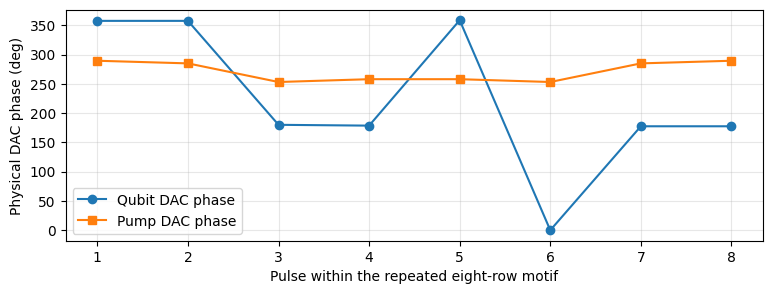

Rounded phases above are the values actually certified; peak pump scale 0.05957622


In [13]:
from pathlib import Path
import hashlib
from verify_scaled_cd import rule
from scaled_cd import motif_score,motif_waveform
recipe=json.load(open(f'{RUNS}/scalable_cd/recipe.json'))
for name,expected in recipe['source_sha256'].items():
    assert hashlib.sha256(Path(name).read_bytes()).hexdigest()==expected,name
parameters=np.asarray(recipe['parameters'])
motif=pd.read_csv(f'{RUNS}/scalable_cd/motif.csv')
display(motif)
fig,ax=plt.subplots(figsize=(9,3))
ax.plot(motif.pulse,motif.qubit_DAC_phase_deg,'o-',label='Qubit DAC phase')
ax.plot(motif.pulse,motif.pump_DAC_phase_deg,'s-',label='Pump DAC phase')
ax.set(xlabel='Pulse within the repeated eight-row motif',ylabel='Physical DAC phase (deg)',xticks=range(1,9))
ax.grid(alpha=.3);ax.legend();plt.show()
print('Rounded phases above are the values actually certified; peak pump scale',recipe['peak_pump_DAC_scale'])

### What was optimized, and what was found

The motif has nine design variables: four first-half qubit-axis offsets,
four first-half pump phases, and one common pump magnitude. The reverse/opposed
qubit half and mirrored pump half are tied. There are no free waveform samples.
A Nelder–Mead fit minimizes **mean infidelity plus maximum infidelity** over
beta=0.2, 0.4, 1 and 2. Every objective call packs actual SDK I/Q and applies the
RFDC filters. One common final Z was allowed during search; the accepted rounded
recipe was subsequently checked with that correction fixed to **zero**.

Seed zero starts from X X Xbar Xbar repeated; the other seeds add small random
axis offsets. Three searches first tried beta=0.5 per motif, then two tried 0.4.
The faster 0.5 choice failed the desired fidelity across larger strengths.
The selected 0.4 seed produces a simple repeatable echo pattern. All phase
offsets are rounded to 0.1 degree and common gain to six decimals before final
verification. The table reports the **rounded recipe's fresh scores**, not its
unrounded optimizer score. Held-out betas and negative signs test scaling.

This family improves both duration and fidelity relative to the matched-strength
reference, using a moderately stronger pump. It does not dominate the independent
fixed-strength library: for example the library beta=1 gate at 0.73 us is more
accurate. Keep those gates when maximum accuracy at that one beta matters more
than one shared sequence rule.

,beta_per_motif,seed,waveform_evaluations,input_column_comparisons,objective,optimizer_status
0,0.5,0,1588,34936,0.023063,Optimization terminated successfully.
1,0.5,1,2244,49368,0.019833,Optimization terminated successfully.
2,0.5,2,2296,50512,0.021629,Optimization terminated successfully.
3,0.4,0,2676,58872,0.010039,Optimization terminated successfully.
4,0.4,1,2132,46904,0.008353,Optimization terminated successfully.


Counted actual waveform objectives: 10936 input columns: 240592


,beta,training_point,repeats,pump_gain,command_us,RFDC_window_us,fidelity,fidelity_nmax8,worst_basis_fidelity,levels
0,-0.500,False,2,-0.625000,0.49,0.534219,0.999267,0.999370,0.998721,96
1,-1.000,False,3,-0.833333,0.73,0.774219,0.998631,0.998834,0.997515,96
2,-2.000,False,5,-1.000000,1.21,1.254219,0.994034,0.995849,0.983269,96
3,0.050,False,1,0.125000,0.25,0.294219,0.999961,0.999968,0.999926,96
4,0.100,False,1,0.250000,0.25,0.294219,0.999864,0.999886,0.999761,96
5,0.125,False,1,0.312500,0.25,0.294219,0.999796,0.999828,0.999658,96
6,0.200,True,1,0.500000,0.25,0.294219,0.999571,0.999631,0.999328,96
7,0.300,False,1,0.750000,0.25,0.294219,0.999133,0.999287,0.998329,96
8,0.400,True,1,1.000000,0.25,0.294219,0.998135,0.998592,0.995657,96
9,0.500,False,2,0.625000,0.49,0.534219,0.999267,0.999370,0.998721,96


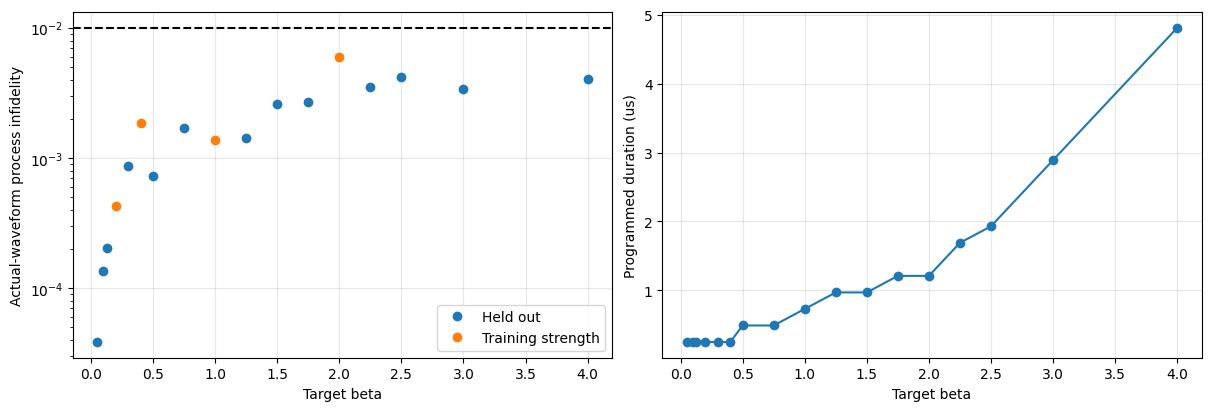

,beta,reference_us,reference_F,reusable_us,reusable_F,speedup
0,1.0,0.81,0.998027,0.73,0.998631,1.109589
1,2.0,1.61,0.992190,1.21,0.994034,1.330579


In [14]:
from glob import glob
fits=[json.load(open(p)) for p in sorted(glob(f'{RUNS}/audit/scalable_motif*seed*.json'))]
fit_table=pd.DataFrame([dict(beta_per_motif=r.get('beta_unit',.5),seed=r['seed'],
                              waveform_evaluations=r['waveform_evaluations'],
                              input_column_comparisons=r['input_column_comparisons'],
                              objective=r['objective'],optimizer_status=r['optimizer_message']) for r in fits])
assert len(fit_table)==5
display(fit_table)
print('Counted actual waveform objectives:',int(fit_table.waveform_evaluations.sum()),
      'input columns:',int(fit_table.input_column_comparisons.sum()))
validation=pd.DataFrame(recipe['results'])
assert len(validation)==20 and np.all(validation.fidelity>.99)
display(validation[['beta','training_point','repeats','pump_gain','command_us','RFDC_window_us',
                    'fidelity','fidelity_nmax8','worst_basis_fidelity','levels']])
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for label,group in validation[validation.beta>0].groupby('training_point'):
    axes[0].semilogy(group.beta,1-group.fidelity,'o',label='Training strength' if label else 'Held out')
axes[0].axhline(.01,color='k',ls='--');axes[0].set(xlabel='Target beta',ylabel='Actual-waveform process infidelity')
axes[0].legend();axes[0].grid(alpha=.3)
positive=validation[validation.beta>0].sort_values('beta')
axes[1].plot(positive.beta,positive.command_us,'o-')
axes[1].set(xlabel='Target beta',ylabel='Programmed duration (us)');axes[1].grid(alpha=.3)
plt.show()
comparison=[]
for beta in [1.,2.]:
    old=native[(native.swap_ns==600)&(native.beta==beta)].iloc[0]
    new=validation[np.isclose(validation.beta,beta)].iloc[0]
    assert new.command_us<old.time_us and new.fidelity>=old.F
    comparison.append(dict(beta=beta,reference_us=old.time_us,reference_F=old.F,
                           reusable_us=new.command_us,reusable_F=new.fidelity,
                           speedup=old.time_us/new.command_us))
display(pd.DataFrame(comparison))

### Fresh playback, fixed frames and enlarged cutoffs

Twenty signed strengths were independently verified on **all 22 inputs**.
The output cutoff increases until both actual and target columns change by
less than 1e-9 in norm; a separate order-16 general solver checks every output
amplitude. The qubit closing frame stays zero during these checks. The next cell
freshly replays four examples in this notebook and compares the stored certificate.
The n<=8 coherent score is also displayed; the n<=10 score is the stricter test.
The worst individual basis fidelity is a separate quantity and need not exceed99%.

In [15]:
fresh=[]
for beta in [.125,1.,2.,4.]:
    saved=validation[np.isclose(validation.beta,beta)].iloc[0]
    M,s=rule(beta)
    result,output,desired,words=motif_score(parameters,M,s,int(saved.levels),True,frame=0.,beta_unit=.4)
    assert abs(result['fidelity']-saved.fidelity)<1e-10
    assert hashlib.sha256(words['qubit'].tobytes()+words['sideband'].tobytes()).hexdigest()==saved.word_sha256
    fresh.append(result)
display(pd.DataFrame(fresh)[['beta','repeats','pump_gain','command_us','fidelity','fidelity_nmax8']])
print('Fresh notebook replay:',len(fresh),'waveforms;',22*len(fresh),'input columns;',
      sum(r['complex_amplitudes'] for r in fresh),'complex amplitudes.')
print('Independent certificate:',recipe['gates'],'gates;',recipe['columns'],'input columns;',
      recipe['independent_amplitudes'],'complex amplitudes.')

,beta,repeats,pump_gain,command_us,fidelity,fidelity_nmax8
0,0.125,1,0.312500,0.25,0.999796,0.999828
1,1.000,3,0.833333,0.73,0.998631,0.998834
2,2.000,5,1.000000,1.21,0.994034,0.995849
3,4.000,20,0.500000,4.81,0.995920,0.996669


Fresh notebook replay: 4 waveforms; 88 input columns; 18304 complex amplitudes.
Independent certificate: 20 gates; 440 input columns; 87296 complex amplitudes.


### What is played at a phase boundary

The qubit DAC phase has the sign conversion applied before packing; the same
integer arrays feed both propagation and the offline compiled schedule.
This plot shows an amplitude-scaled beta=1 waveform at a phase boundary. The
FIR response is a linear baseband model; no instantaneous phase jump is assumed
in propagation. The Wigner panels below use the freshly propagated beta=4
vacuum input, postselected and normalized separately in each qubit branch.

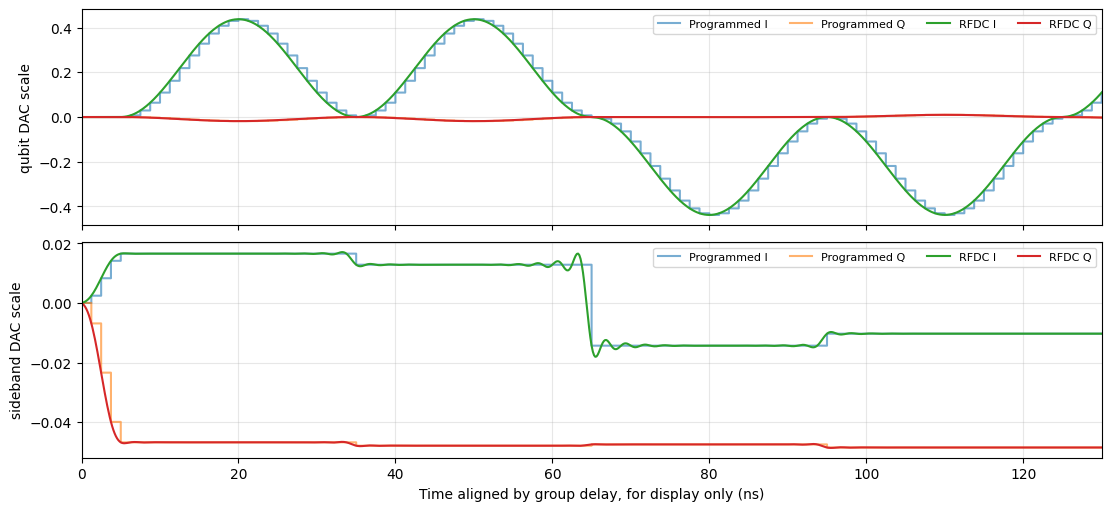

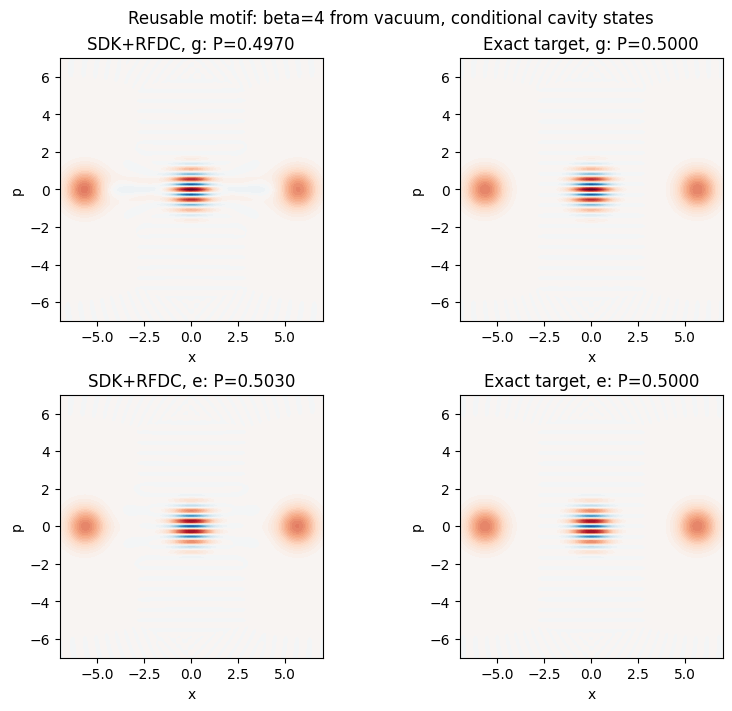

In [16]:
from acadia.sample_arithmetic import sample_to_complex
M,s=rule(1.)
q,sb,words=motif_waveform(parameters,M,s)
fig,axes=plt.subplots(2,1,figsize=(11,5),sharex=True,constrained_layout=True)
for ax,key in zip(axes,['qubit','sideband']):
    programmed=sample_to_complex(words[key]);filtered=hw.rfdc_interpolate(programmed)
    t=np.arange(len(programmed))*cd.DT*1000
    tout=np.arange(len(filtered))*cd.DT/8*1000-cp.GROUP_DELAY_NS
    ax.step(t,programmed.real,where='post',label='Programmed I',alpha=.6)
    ax.step(t,programmed.imag,where='post',label='Programmed Q',alpha=.6)
    ax.plot(tout,filtered.real,label='RFDC I');ax.plot(tout,filtered.imag,label='RFDC Q')
    ax.set(xlim=(0,130),ylabel=key+' DAC scale');ax.grid(alpha=.3);ax.legend(ncol=4,fontsize=8)
axes[-1].set_xlabel('Time aligned by group delay, for display only (ns)');plt.show()
# output and desired from the previous cell are the beta=4 arrays.
grid=np.linspace(-7,7,181)
fig,axes=plt.subplots(2,2,figsize=(8,7),constrained_layout=True)
for row,branch in enumerate(['g','e']):
    for col,(name,state) in enumerate([('SDK+RFDC',output[:,0]),('Exact target',desired[:,0])]):
        ket=state[row::2];probability=float(np.vdot(ket,ket).real);ket=ket/np.sqrt(probability)
        W=cp.qt.wigner(cp.qt.Qobj(ket[:,None]),grid,grid)
        axes[row,col].contourf(grid,grid,W,60,cmap='RdBu_r',vmin=-1/np.pi,vmax=1/np.pi)
        axes[row,col].set_aspect('equal');axes[row,col].set_title(f'{name}, {branch}: P={probability:.4f}')
        axes[row,col].set(xlabel='x',ylabel='p')
fig.suptitle('Reusable motif: beta=4 from vacuum, conditional cavity states');plt.show()